**Dashboard Implementation (The "Final Product")**  

*Network Visualization (The "Villa Sociogram")*
- Time Selector: Granular toggling (Weekly default, scalable to custom event-based windows).
- Nodes: Size-weighted by mention_share, color-coded by Louvain_cluster.
- Edges: Weighted by co-mention_count.
- Tooltips: Deep-dive metadata including LLM-distilled perspectives, toxicity scores, and approval/polarization metrics.

*Temporal Tracking (The "Contestant Arc")*
- Line-Chart Interface: Multi-line visualization tracking contestant-specific metrics over time.
- Dynamic Metric Toggles:
    - Sentiment Velocity: Tracking the 1–5 LLM-distilled sentiment score.
    - Attention Share: Plotting the % of discourse captured by a specific contestant.
    - Polarization Index: Visualizing the weekly standard deviation of sentiment to flag controversial peaks.
- Annotation Layer: Automated markers on the X-axis for "Villa Events" (e.g., Recoupling, Dumpings, Bombshell Entry) to correlate community sentiment shifts with show production milestones.

## Survival dataset — explore before choosing a model

**No models are fitted in this section.** Final exits are dumpings; finalists are censored at episode 35. Temporary exits are not final-exit events. Presence-spell data are unavailable, so intervals represent time until final exit rather than confirmed physical presence.

Three inspectable datasets:

- `survival_subjects`: one row per islander, entrance, final exit, original-cast/bombshell metadata, duration, event and censoring.
- `survival_intervals`: one row per islander per episode of follow-up. `target_episode` is the episode whose exit outcome is recorded; `feature_episode = target_episode - 1`. `start`/`stop` are tenure-based counting-process intervals. `calendar_start`/`calendar_stop` provide season-episode time with delayed entry. `event` is 1 only on final exit. Eight finalists finish with `censored_at_stop = 1`. Entry intervals have no prior contestant observations; `prediction_eligible` identifies the 503 post-entry rows for next-episode logistic exploration.
- `survival_baseline_covariates`: fixed covariates from the first post-entry observation, for a possible **landmark Cox model conditional on surviving entry**, with `baseline_entry_time = 1`. Do not use these covariates to explain survival before that landmark. Later time-varying Cox work can instead use the interval table. Neither dataset supplies a fitted probability.

**Candidate covariates (`asof_`):** comment counts/log counts, attention share, VADER/RoBERTa means and SDs, toxicity/insult, toxic-comment share, sentiment z-scores, and changes. Repeated windows are averaged within comment before aggregation. Toxic-comment share here thresholds the comment-average toxicity at 0.5. Attention share is the share of comment–islander assignments in that feature episode, not unique Reddit comments. Z-scores compare cutoff-filtered means among the recorded risk set for the same target episode. Missing sentiment is left missing; no comments is recorded as zero count plus `asof_has_comments=False`. Entry intervals have no prior in-study features.

**Timing:** comments must precede the earliest observed comment in the target episode's threads. `cutoff_proxy` and `asof_latest_timestamp` let you inspect this rule. This is a retrospective timing proxy, not verified airtime. Timestamp filtering cannot rule out leaks/spoilers already present in comments. Censoring/entry assumptions and correlated couple/group exits will need consideration when modeling.

**Exploration covariates (`explore_`):** complete saved episode sentiment summaries, network centralities/communities/emojis, Kalshi prices and LLM approval. These are joined to the prior episode but are **not automatically prediction-safe**: late replies, market aggregation timing, or multi-episode LLM context can leak later information. Keep them available to explore; audit or rebuild them before predictive use.

**Outcomes are not predictors:** exit dates, duration, final placement, event flags and censoring belong to the outcome definition. `survival_feature_dictionary` marks column roles and missingness. No automatic feature selection, imputation, regression or survival fitting runs here. Old `final_exit_*` model artifacts remain historical and are not refreshed or used by this section.

All five dataset/audit tables are saved to DuckDB under `dashboard.survival_*` and CSV under `tables/survival_dashboard/`.


In [2]:
from pathlib import Path
import importlib.util
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
spec = importlib.util.spec_from_file_location("survival_builder", project_root / "code/build_survival_dataset.py")
survival_builder = importlib.util.module_from_spec(spec)
spec.loader.exec_module(survival_builder)
survival_tables = survival_builder.build_survival_dataset(project_root)
survival_subjects = survival_tables["survival_subjects"]
survival_intervals = survival_tables["survival_intervals"]
survival_baseline_covariates = survival_tables["survival_baseline_covariates"]
survival_feature_dictionary = survival_tables["survival_feature_dictionary"]
survival_feature_timing_audit = survival_tables["survival_feature_timing_audit"]
display(survival_subjects)


34 subjects; 537 intervals; 26 final exits; 8 finale censorings.
503 post-entry rows available for next-episode exploration. No model fitted.


,target_islander,entrance_episode,entrance_day,exit_episode,exit_day,original_cast,bombshell,final_placement,event_observed,censored,duration_episodes
0,Alannah Keyser,10,10,19,19,False,True,NaN,1,0,10
1,Amora Cacheé Robinson,17,17,25,25,False,True,NaN,1,0,9
2,Aniya Harvey,1,1,35,32,True,False,Runner-up,0,1,35
3,Beatriz Hatz,1,1,10,10,True,False,NaN,1,0,10
4,Bryce Alakai Dettloff,1,1,35,32,True,False,Winner,0,1,35
5,Caleb McDaniel,13,13,25,25,False,True,NaN,1,0,13
6,Carl Lee Schmidt,20,20,35,32,False,True,Runner-up,0,1,16
7,Chandlar Wilson,10,10,17,17,False,True,NaN,1,0,8
8,Chaten Nehra,17,17,20,20,False,True,NaN,1,0,4
9,Corbin Mims,10,10,26,26,False,True,NaN,1,0,17


In [3]:
# Change this name to inspect any islander's complete episode history.
islander_to_inspect = "Mackenzie Annis"
inspection_columns = [
    "target_islander", "feature_episode", "target_episode", "start", "stop",
    "event", "censored_at_stop", "prediction_eligible", "asof_num_comments",
    "asof_vader_mean", "asof_roberta_mean", "asof_roberta_z",
    "asof_roberta_sd", "asof_toxicity_mean", "asof_attention_share",
    "explore_network_weighted_degree", "explore_market_kalshi_price",
    "explore_llm_approval", "cutoff_proxy", "asof_latest_timestamp",
]
display(survival_intervals.loc[
    survival_intervals.target_islander.eq(islander_to_inspect), inspection_columns
])

# Explore candidate covariates without fitting anything.
candidate_columns = [c for c in survival_intervals if c.startswith("asof_")
                     and pd.api.types.is_numeric_dtype(survival_intervals[c])]
display(survival_intervals.loc[survival_intervals.prediction_eligible, candidate_columns].describe().T)
display(survival_feature_dictionary.sort_values("missing_rows", ascending=False))


,target_islander,feature_episode,target_episode,start,stop,event,censored_at_stop,prediction_eligible,asof_num_comments,asof_vader_mean,asof_roberta_mean,asof_roberta_z,asof_roberta_sd,asof_toxicity_mean,asof_attention_share,explore_network_weighted_degree,explore_market_kalshi_price,explore_llm_approval,cutoff_proxy,asof_latest_timestamp
303,Mackenzie Annis,0,1,0,1,0,0,False,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,<NA>,2026-06-02 17:20:04,NaT
304,Mackenzie Annis,1,2,1,2,0,0,True,674,0.130882,-0.153613,-1.157643,0.594697,0.082150,0.171676,551.0,14.53,0,2026-06-03 17:20:06,2026-06-03 15:11:38
305,Mackenzie Annis,2,3,2,3,0,0,True,455,0.124997,-0.212092,-0.140283,0.565514,0.084135,0.214927,458.0,15.00,<NA>,2026-06-04 17:20:05,2026-06-04 15:27:37
306,Mackenzie Annis,3,4,3,4,0,0,True,670,0.103390,-0.313553,-0.816534,0.528162,0.100657,0.189480,715.0,12.97,1,2026-06-05 17:20:07,2026-06-05 16:46:13
307,Mackenzie Annis,4,5,4,5,0,0,True,609,0.128817,-0.247449,-0.361110,0.540657,0.084908,0.114949,1186.0,12.93,<NA>,2026-06-07 17:20:06,2026-06-07 16:38:12
308,Mackenzie Annis,5,6,5,6,0,0,True,637,0.089375,-0.282284,-1.210535,0.517186,0.111862,0.120279,798.0,27.02,1,2026-06-08 17:20:09,2026-06-08 17:07:02
309,Mackenzie Annis,6,7,6,7,0,0,True,412,0.128462,-0.199712,-0.487891,0.527924,0.114953,0.108650,331.0,39.99,0,2026-06-09 17:20:24,2026-06-09 10:00:21
310,Mackenzie Annis,7,8,7,8,0,0,True,515,0.127312,-0.199091,-0.098104,0.532742,0.087403,0.070278,720.0,16.67,1,2026-06-11 17:33:49,2026-06-10 08:38:35
311,Mackenzie Annis,8,9,8,9,0,0,True,706,0.014147,-0.413803,-0.274098,0.421668,0.113453,0.092312,945.0,14.08,0,2026-06-12 17:19:39,2026-06-12 16:33:38
312,Mackenzie Annis,9,10,9,10,0,0,True,248,0.094477,-0.292335,0.272391,0.547768,0.120528,0.053322,274.0,14.99,<NA>,2026-06-13 17:34:23,2026-06-13 16:20:34


,count,mean,std,min,25%,50%,75%,max
asof_num_comments,503.0,3.787356e+02,378.729123,0.000000,77.000000,275.000000,560.500000,2252.000000
asof_vader_mean,447.0,8.857875e-02,0.097925,-0.312000,0.021028,0.084492,0.156606,0.377954
asof_vader_sd,442.0,4.539398e-01,0.044188,0.015486,0.442456,0.459286,0.474159,0.661336
asof_roberta_mean,447.0,-2.485393e-01,0.199491,-0.787488,-0.398015,-0.295133,-0.107105,0.438129
asof_roberta_sd,442.0,5.357063e-01,0.086337,0.039472,0.477965,0.535710,0.600552,0.708705
asof_toxicity_mean,447.0,1.249344e-01,0.067274,0.000711,0.087065,0.113923,0.150970,0.835847
asof_insult_mean,447.0,5.387411e-02,0.032211,0.000167,0.033976,0.046751,0.068043,0.231483
asof_toxic_comment_share,447.0,1.092343e-01,0.082421,0.000000,0.070439,0.098655,0.133424,1.000000
asof_attention_share,447.0,6.439508e-02,0.046670,0.000117,0.030168,0.053761,0.089327,0.279351
asof_log_comments,503.0,4.884200e+00,2.143045,0.000000,4.356380,5.620401,6.330580,7.720018


,column,role,missing_rows,dtype
16,final_placement,outcome_only_never_predictor,278,object
72,explore_llm_approval,exploration_only_timing_or_future_context_unve...,155,Int64
81,asof_toxicity_mean_change,candidate_cutoff_filtered,121,float64
80,asof_vader_mean_change,candidate_cutoff_filtered,121,float64
79,asof_roberta_mean_change,candidate_cutoff_filtered,121,float32
...,...,...,...,...
32,asof_log_comments,candidate_cutoff_filtered,0,float64
33,prediction_eligible,identifier_time_or_baseline_metadata,0,bool
34,outcome_next_episode,outcome_only_never_predictor,0,int64
1,target_episode,identifier_time_or_baseline_metadata,0,int64


### Co-mention covariates

Connections describe shared discussion, not romantic relationships. The dataset builder uses simple loops to rank connections separately for each islander and feature episode. All counts use distinct comments from the same lightly cleaned windows, before the prediction cutoff.

- **Top-1 share**: comments mentioning the strongest connection / comments mentioning the target.
- **Top-2 share**: comments mentioning either of the two strongest connections / comments mentioning the target. A comment mentioning both counts once.
- **Dominance gap**: top-1 share minus the second connection's individual share.
- **Adjusted overall strength**: average number of other islanders mentioned per target comment. This can exceed 1.

Both models include top-1 share and adjusted overall strength. Top-2 share, the gap, connection names, and tie counts are saved for exploration. Ties are broken alphabetically; a tie count greater than 1 means there is no unique strongest connection. No co-mentions gives zero shares; no target comments leaves shares missing.

Baseline Cox uses first-post-entry features; logistic uses previous-episode features. No above/below-average threshold is required: the model receives continuous shares.

In [ ]:
# Inspect the connections used to predict the following episode.
connection_columns = [
    "target_islander",
    "feature_episode",
    "target_episode",
    "asof_num_comments",
    "asof_top1_connection",
    "asof_top2_connection",
    "asof_top1_comention_share",
    "asof_top2_comention_share",
    "asof_connection_dominance_gap",
    "asof_top1_tie_count",
    "asof_comention_strength_per_comment",
]
connection_preview = survival_intervals[connection_columns].copy()
connection_preview = connection_preview.sort_values(["target_islander", "feature_episode"])
display(connection_preview.head(20))

target_islander,feature_episode,target_episode,asof_num_comments,asof_top1_connection,asof_top2_connection,asof_top1_comention_share,asof_top2_comention_share,asof_connection_dominance_gap,asof_top1_tie_count,asof_comention_strength_per_comment
Alannah Keyser,9,10,0,None,None,NaN,NaN,NaN,NaN,NaN
Alannah Keyser,10,11,0,None,None,NaN,NaN,NaN,NaN,NaN
Alannah Keyser,11,12,0,None,None,NaN,NaN,NaN,NaN,NaN
Alannah Keyser,12,13,0,None,None,NaN,NaN,NaN,NaN,NaN
Alannah Keyser,13,14,0,None,None,NaN,NaN,NaN,NaN,NaN
Alannah Keyser,14,15,0,None,None,NaN,NaN,NaN,NaN,NaN
Alannah Keyser,15,16,0,None,None,NaN,NaN,NaN,NaN,NaN
Alannah Keyser,16,17,1,Gabriel Vasconcelos,None,1.000000,1.000000,1.000000,1.0,1.000000
Alannah Keyser,17,18,180,Bryce Alakai Dettloff,Kuman Chandler,0.072222,0.111111,0.005556,1.0,0.472222
Alannah Keyser,18,19,275,Zacharias Georgiou,Kayda Bosse,0.367273,0.392727,0.265455,1.0,0.727273


## 1. Load the modeling datasets and choose covariates

All modeling is written inline below. Kaplan–Meier is an unadjusted descriptive curve. Cox is a penalized **baseline landmark model**, conditional on completing the entrance episode; baseline covariates stay fixed. Logistic regression uses changing prior-episode covariates and chronological held-out predictions. These are distinct estimands, not interchangeable probabilities.

Use only `asof_` covariates; never final placement, future exit dates, whole-season summaries, or `explore_` fields as predictors. Episode cutoff timestamps remain retrospective proxies. This single season has 34 people, correlated/group exits, specials and no temporary-presence spells; all results are exploratory. No API calls or pretrained sentiment reruns occur.

In [ ]:
from pathlib import Path
import json
import hashlib
import platform
import numpy as np
import pandas as pd
import duckdb
import lifelines
import sklearn
import matplotlib.pyplot as plt
from lifelines import KaplanMeierFitter
from lifelines import CoxPHFitter
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import brier_score_loss
from sklearn.metrics import log_loss
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

database_path = project_root / "data" / "love_island_reddit.duckdb"
probability_export_directory = project_root / "tables" / "survival_dashboard"
probability_export_directory.mkdir(parents=True, exist_ok=True)

with duckdb.connect(str(database_path), read_only=True) as connection:
    survival_subjects = connection.execute("SELECT * FROM dashboard.survival_subjects ORDER BY target_islander").df()
    survival_intervals = connection.execute("SELECT * FROM dashboard.survival_intervals ORDER BY target_islander, target_episode").df()
    survival_baseline_covariates = connection.execute("SELECT * FROM dashboard.survival_baseline_covariates ORDER BY target_islander").df()

# Keep the first model small. Edit these lists to explore another specification.
cox_covariates = [
    "asof_log_comments",
    "asof_roberta_mean",
    "asof_toxicity_mean",
    "asof_comention_strength_per_comment",
    "asof_top1_comention_share",
]
logistic_covariates = [
    "feature_episode",
    "start",
    "asof_log_comments",
    "asof_roberta_mean",
    "asof_toxicity_mean",
    "asof_comention_strength_per_comment",
    "asof_top1_comention_share",
]
cox_penalty = 0.50
logistic_inverse_penalty = 0.25
minimum_training_events = 3
model_version = "inline_survival_v3_top_connection"
model_run_time = pd.Timestamp.now(tz="UTC").isoformat()

assert survival_subjects["target_islander"].is_unique
assert survival_subjects["event_observed"].sum() == 26
assert survival_intervals["censored_at_stop"].sum() == 8
assert survival_intervals["event"].sum() == 26

available_timestamps = survival_intervals["asof_latest_timestamp"].notna()
latest_feature_times = survival_intervals.loc[available_timestamps, "asof_latest_timestamp"]
prediction_cutoffs = survival_intervals.loc[available_timestamps, "cutoff_proxy"]
assert latest_feature_times.lt(prediction_cutoffs).all()

display(survival_baseline_covariates[cox_covariates].isna().sum().rename("missing_baseline_values").to_frame())

,missing_baseline_values
asof_log_comments,0
asof_roberta_mean,13
asof_toxicity_mean,13
asof_comention_strength_per_comment,13
asof_top1_comention_share,13


## 2. Estimate unadjusted survival with Kaplan–Meier

Time is episodes since entrance, inclusive. Eight finalists are right-censored. The curve and nominal 95% intervals describe the full observed season; strategic entry/censoring and shared dumpings limit the usual independence assumptions. `1 − survival_probability` means cumulative probability of final exit **by that tenure**, not next-episode risk.

In [ ]:
kaplan_meier_model = KaplanMeierFitter()
kaplan_meier_model.fit(
    durations=survival_subjects["duration_episodes"],
    event_observed=survival_subjects["event_observed"],
    label="survival_probability",
)

km_survival_probabilities = kaplan_meier_model.survival_function_.copy()
km_survival_probabilities = km_survival_probabilities.join(kaplan_meier_model.confidence_interval_)
km_survival_probabilities = km_survival_probabilities.join(kaplan_meier_model.event_table)
km_survival_probabilities.index.name = "tenure_episode"
km_survival_probabilities = km_survival_probabilities.reset_index()
km_survival_probabilities["booted_by_tenure_probability"] = 1 - km_survival_probabilities["survival_probability"]
km_survival_probabilities["estimate_type"] = "full_season_descriptive"

display(km_survival_probabilities)

,tenure_episode,survival_probability,survival_probability_lower_0.95,survival_probability_upper_0.95,removed,observed,censored,entrance,at_risk,booted_by_tenure_probability,estimate_type
0,0.0,1.000000,1.000000,1.000000,0,0,0,34,34,0.000000,full_season_descriptive
1,4.0,0.882353,0.716269,0.954139,4,4,0,0,34,0.117647,full_season_descriptive
2,5.0,0.852941,0.682146,0.935994,1,1,0,0,30,0.147059,full_season_descriptive
3,6.0,0.794118,0.616102,0.896087,2,2,0,0,29,0.205882,full_season_descriptive
4,8.0,0.617647,0.434220,0.757062,6,6,0,0,27,0.382353,full_season_descriptive
5,9.0,0.558824,0.378248,0.705877,2,2,0,0,21,0.441176,full_season_descriptive
6,10.0,0.470588,0.298307,0.625186,3,3,0,0,19,0.529412,full_season_descriptive
7,11.0,0.441176,0.272737,0.597261,1,1,0,0,16,0.558824,full_season_descriptive
8,12.0,0.411765,0.247723,0.568816,1,1,0,0,15,0.588235,full_season_descriptive
9,13.0,0.352941,0.199440,0.510306,2,2,0,0,14,0.647059,full_season_descriptive


## 3. Prepare fixed baseline covariates for Cox

Use first-post-entry measurements, available at the start of the second tenure interval. This is a landmark analysis conditional on survival to tenure 1, not a model using current sentiment at every later episode. Thirteen contestants currently have no baseline sentiment observations; retain them using median imputation and one explicit missing-discussion indicator. These descriptive preprocessing values are fitted to the full baseline cohort and saved for reproducibility.

In [ ]:
eligible_baselines = survival_baseline_covariates["baseline_available"].fillna(False)
cox_baseline_dataset = survival_baseline_covariates.loc[eligible_baselines].copy()
cox_baseline_dataset = cox_baseline_dataset.set_index("target_islander")
assert cox_baseline_dataset["duration_episodes"].gt(cox_baseline_dataset["baseline_entry_time"]).all()

cox_raw_features = cox_baseline_dataset[cox_covariates].copy()
cox_imputation_values = cox_raw_features.median()
cox_imputation_values = cox_imputation_values.fillna(0)
cox_prepared_features = cox_raw_features.fillna(cox_imputation_values)
cox_missing_discussion = cox_raw_features["asof_roberta_mean"].isna()
cox_prepared_features["missing_baseline_discussion"] = cox_missing_discussion.astype(int)

cox_feature_standard_deviations = cox_prepared_features.std(ddof=0)
cox_variable_columns = cox_feature_standard_deviations.gt(0)
cox_retained_features = cox_feature_standard_deviations.index[cox_variable_columns].tolist()
cox_prepared_features = cox_prepared_features[cox_retained_features]

cox_scaler = StandardScaler()
cox_scaled_values = cox_scaler.fit_transform(cox_prepared_features)
cox_scaled_features = pd.DataFrame(cox_scaled_values, index=cox_prepared_features.index, columns=cox_retained_features)

cox_fit_dataset = cox_scaled_features.copy()
cox_fit_dataset["duration_episodes"] = cox_baseline_dataset["duration_episodes"]
cox_fit_dataset["event_observed"] = cox_baseline_dataset["event_observed"]
cox_fit_dataset["baseline_entry_time"] = cox_baseline_dataset["baseline_entry_time"]

cox_preprocessing = pd.DataFrame({"feature": cox_retained_features})
cox_preprocessing["imputation_value"] = cox_preprocessing["feature"].map(cox_imputation_values)
cox_preprocessing["scaling_mean"] = cox_scaler.mean_
cox_preprocessing["scaling_sd"] = cox_scaler.scale_

display(cox_fit_dataset.head())

,asof_log_comments,asof_roberta_mean,asof_toxicity_mean,asof_comention_strength_per_comment,asof_top1_comention_share,missing_baseline_discussion,duration_episodes,event_observed,baseline_entry_time
target_islander,,,,,,,,,
Alannah Keyser,-1.185155,-0.101460,-0.229666,-0.135977,0.027117,1.270978,10,1,1
Amora Cacheé Robinson,0.281901,1.482989,2.192748,-2.352725,-2.333931,-0.786796,9,1,1
Aniya Harvey,0.765225,1.842145,-1.128481,1.050719,0.898372,-0.786796,35,0,1
Beatriz Hatz,0.975956,1.749438,-0.229666,-0.498245,-0.982937,-0.786796,10,1,1
Bryce Alakai Dettloff,0.984075,-0.400755,-0.861107,-0.759513,-0.502617,-0.786796,35,0,1


## 4. Fit a penalized Cox model

Shrinkage stabilizes a small dataset; it does not establish predictive validity or causality. Hazard ratios are **not probabilities**. This full-season fit is descriptive, not evaluated out of time. Proportional hazards, strategic entry, tied/group exits and missing baseline discussion remain limitations; do not interpret nominal p-values as definitive evidence. [Lifelines Cox documentation](https://lifelines.readthedocs.io/en/latest/fitters/regression/CoxPHFitter.html).

In [ ]:
cox_model = CoxPHFitter(penalizer=cox_penalty)
cox_model.fit(
    cox_fit_dataset,
    duration_col="duration_episodes",
    event_col="event_observed",
    entry_col="baseline_entry_time",
)

cox_coefficient_summary = cox_model.summary.copy()
cox_coefficient_summary.index.name = "feature"
cox_coefficient_summary = cox_coefficient_summary.reset_index()
cox_coefficient_summary["fit_type"] = "full_season_baseline_landmark_descriptive"

cox_baseline_hazard = cox_model.baseline_cumulative_hazard_.copy()
cox_baseline_hazard.index.name = "tenure_episode"
cox_baseline_hazard = cox_baseline_hazard.reset_index()

display(cox_coefficient_summary[["feature", "coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%"]])

,feature,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%
0,asof_log_comments,-0.298693,0.741787,0.514392,1.069707
1,asof_roberta_mean,-0.167094,0.846120,0.602144,1.188950
2,asof_toxicity_mean,0.116408,1.123455,0.842533,1.498043
3,asof_comention_strength_per_comment,-0.048539,0.952620,0.668748,1.356991
4,asof_top1_comention_share,-0.241204,0.785682,0.547472,1.127538
5,missing_baseline_discussion,0.246570,1.279629,0.883475,1.853420


## 5. Calculate adjusted survival probabilities

Cox survival curves are conditional on reaching the baseline landmark at tenure 1. We obtain probabilities from the fitted survival function—not from hazard ratios. Curves cover observed tenure support only, and omit hypothetical calendar episodes after the finale. Values beyond an individual's observed exit are model-implied curves, not actual continued eligibility; `within_observed_followup` records that distinction.

In [ ]:
maximum_tenure = int(survival_subjects["duration_episodes"].max())
cox_prediction_times = np.arange(1, maximum_tenure + 1)
cox_survival_wide = cox_model.predict_survival_function(cox_scaled_features, times=cox_prediction_times)
cox_landmark_survival = cox_survival_wide.loc[1]
cox_conditional_survival = cox_survival_wide.divide(cox_landmark_survival, axis="columns")
cox_conditional_survival = cox_conditional_survival.clip(lower=0, upper=1)
cox_conditional_survival.index.name = "tenure_episode"
cox_survival_probabilities = cox_conditional_survival.reset_index()
cox_survival_probabilities = cox_survival_probabilities.melt(
    id_vars="tenure_episode",
    var_name="target_islander",
    value_name="survival_probability",
)

subject_followup = survival_subjects[["target_islander", "entrance_episode", "duration_episodes"]]
cox_survival_probabilities = cox_survival_probabilities.merge(subject_followup, on="target_islander", validate="many_to_one")
cox_survival_probabilities["calendar_episode"] = cox_survival_probabilities["entrance_episode"] + cox_survival_probabilities["tenure_episode"] - 1
within_season = cox_survival_probabilities["calendar_episode"].le(35)
cox_survival_probabilities = cox_survival_probabilities.loc[within_season].copy()
cox_survival_probabilities["booted_by_tenure_probability"] = 1 - cox_survival_probabilities["survival_probability"]
cox_survival_probabilities["within_observed_followup"] = cox_survival_probabilities["tenure_episode"].le(cox_survival_probabilities["duration_episodes"])
cox_survival_probabilities["landmark_tenure"] = 1
cox_survival_probabilities["estimate_type"] = "full_season_baseline_landmark_descriptive"

display(cox_survival_probabilities.head())

,tenure_episode,target_islander,survival_probability,entrance_episode,duration_episodes,calendar_episode,booted_by_tenure_probability,within_observed_followup,landmark_tenure,estimate_type
0,1.0,Alannah Keyser,1.000000,10,10,10.0,0.000000,True,1,full_season_baseline_landmark_descriptive
1,2.0,Alannah Keyser,1.000000,10,10,11.0,0.000000,True,1,full_season_baseline_landmark_descriptive
2,3.0,Alannah Keyser,1.000000,10,10,12.0,0.000000,True,1,full_season_baseline_landmark_descriptive
3,4.0,Alannah Keyser,1.000000,10,10,13.0,0.000000,True,1,full_season_baseline_landmark_descriptive
4,5.0,Alannah Keyser,0.944544,10,10,14.0,0.055456,True,1,full_season_baseline_landmark_descriptive


## 6. Prepare next-episode logistic observations

A logistic row predicts final exit in `target_episode`, using only `feature_episode = target_episode − 1`. Entry intervals have no prior contestant observations and are excluded. Retain zero-comment rows and missingness indicators. Do not use class balancing: it can distort probabilities. Do not multiply these dynamically refitted one-step predictions into a claimed future season-long survival curve.

In [ ]:
eligible_prediction_rows = survival_intervals["prediction_eligible"]
logistic_dataset = survival_intervals.loc[eligible_prediction_rows].copy()
logistic_dataset = logistic_dataset.sort_values(["target_episode", "target_islander"])
logistic_dataset = logistic_dataset.reset_index(drop=True)

logistic_feature_dataset = logistic_dataset[logistic_covariates].copy()
logistic_missing_discussion = logistic_feature_dataset["asof_roberta_mean"].isna()
logistic_feature_dataset["missing_discussion"] = logistic_missing_discussion.astype(int)
logistic_model_features = logistic_feature_dataset.columns.tolist()

prediction_identity_columns = ["target_islander", "feature_episode", "target_episode", "start", "stop", "event", "cutoff_proxy", "asof_num_comments"]
logistic_episode_probabilities = logistic_dataset[prediction_identity_columns].copy()
logistic_episode_probabilities["booted_next_episode_probability"] = np.nan
logistic_episode_probabilities["survive_next_episode_probability"] = np.nan
logistic_episode_probabilities["baseline_booted_probability"] = np.nan
logistic_episode_probabilities["training_last_outcome_episode"] = pd.Series(pd.NA, index=logistic_dataset.index, dtype="Int64")
logistic_episode_probabilities["prediction_status"] = "warmup_no_prediction"
logistic_episode_probabilities["estimate_type"] = "chronological_out_of_time"

fold_records = []
logistic_coefficient_records = []
logistic_preprocessing_records = []

## 7. Fit logistic regression using earlier outcomes only

At the cutoff before target episode k, only outcomes through k−1 are used. Every contestant in target episode k is held out together. Scaling and median imputation are learned from training rows only. Early episodes remain explicitly unpredicted until at least three historical events and both outcome classes exist. This is an exploratory chronological test within one season, not an independent-season validation.

In [ ]:
prediction_episodes = logistic_dataset["target_episode"].unique()

for target_episode in prediction_episodes:
    training_mask = logistic_dataset["target_episode"].lt(target_episode)
    testing_mask = logistic_dataset["target_episode"].eq(target_episode)

    training_features = logistic_feature_dataset.loc[training_mask].copy()
    testing_features = logistic_feature_dataset.loc[testing_mask].copy()
    training_outcomes = logistic_dataset.loc[training_mask, "event"]
    training_event_count = int(training_outcomes.sum())
    training_class_count = training_outcomes.nunique()

    fold_record = {
        "target_episode": int(target_episode),
        "training_rows": len(training_outcomes),
        "training_events": training_event_count,
        "test_rows": int(testing_mask.sum()),
        "status": "warmup_no_prediction",
    }

    if training_event_count < minimum_training_events or training_class_count < 2:
        fold_records.append(fold_record)
        continue

    # Fallback to zero only when an entire training feature is missing.
    training_imputation_values = training_features.median()
    training_imputation_values = training_imputation_values.fillna(0)
    training_features = training_features.fillna(training_imputation_values)
    testing_features = testing_features.fillna(training_imputation_values)

    logistic_scaler = StandardScaler()
    scaled_training_features = logistic_scaler.fit_transform(training_features)
    scaled_testing_features = logistic_scaler.transform(testing_features)

    logistic_model = LogisticRegression(C=logistic_inverse_penalty, max_iter=2000, random_state=42)
    logistic_model.fit(scaled_training_features, training_outcomes)
    predicted_probabilities = logistic_model.predict_proba(scaled_testing_features)
    booted_probabilities = predicted_probabilities[:, 1]

    # Laplace smoothing produces a finite training-only baseline probability.
    baseline_probability = (training_event_count + 1) / (len(training_outcomes) + 2)
    training_last_episode = logistic_dataset.loc[training_mask, "target_episode"].max()
    assert training_last_episode < target_episode

    logistic_episode_probabilities.loc[testing_mask, "booted_next_episode_probability"] = booted_probabilities
    logistic_episode_probabilities.loc[testing_mask, "survive_next_episode_probability"] = 1 - booted_probabilities
    logistic_episode_probabilities.loc[testing_mask, "baseline_booted_probability"] = baseline_probability
    logistic_episode_probabilities.loc[testing_mask, "training_last_outcome_episode"] = int(training_last_episode)
    logistic_episode_probabilities.loc[testing_mask, "prediction_status"] = "predicted"

    fold_record["status"] = "predicted"
    fold_record["training_last_outcome_episode"] = int(training_last_episode)
    fold_records.append(fold_record)

    for feature_index, feature_name in enumerate(logistic_model_features):
        logistic_coefficient_records.append({
            "target_episode": int(target_episode),
            "feature": feature_name,
            "standardized_coefficient": float(logistic_model.coef_[0, feature_index]),
            "intercept": float(logistic_model.intercept_[0]),
        })
        logistic_preprocessing_records.append({
            "target_episode": int(target_episode),
            "feature": feature_name,
            "imputation_value": float(training_imputation_values[feature_name]),
            "scaling_mean": float(logistic_scaler.mean_[feature_index]),
            "scaling_sd": float(logistic_scaler.scale_[feature_index]),
        })

logistic_folds = pd.DataFrame(fold_records)
logistic_coefficients = pd.DataFrame(logistic_coefficient_records)
logistic_preprocessing = pd.DataFrame(logistic_preprocessing_records)
display(logistic_folds)

,target_episode,training_rows,training_events,test_rows,status,training_last_outcome_episode
0,2,0,0,10,warmup_no_prediction,NaN
1,3,10,0,10,warmup_no_prediction,NaN
2,4,20,0,13,warmup_no_prediction,NaN
3,5,33,0,13,warmup_no_prediction,NaN
4,6,46,0,13,warmup_no_prediction,NaN
5,7,59,1,12,warmup_no_prediction,NaN
6,8,71,1,12,warmup_no_prediction,NaN
7,9,83,1,12,warmup_no_prediction,NaN
8,10,95,1,12,warmup_no_prediction,NaN
9,11,107,2,20,warmup_no_prediction,NaN


## 8. Evaluate probabilities and inspect calibration

Evaluate only chronological predictions. Lower Brier score/log loss are better. Compare both models on the same rows. Calibration bins are descriptive and can be sparse; no post-hoc calibration is fitted to these test outcomes. Cox and Kaplan–Meier are not included in this held-out comparison because they were fitted on the full season.

In [ ]:
predicted_rows = logistic_episode_probabilities["prediction_status"].eq("predicted")
evaluated_predictions = logistic_episode_probabilities.loc[predicted_rows].copy()
observed_outcomes = evaluated_predictions["event"]
evaluation_records = []

probability_columns = {
    "logistic": "booted_next_episode_probability",
    "training_rate_baseline": "baseline_booted_probability",
}

for model_name, probability_column in probability_columns.items():
    model_probabilities = evaluated_predictions[probability_column]
    evaluation_record = {
        "model": model_name,
        "test_rows": len(evaluated_predictions),
        "observed_exits": int(observed_outcomes.sum()),
        "brier_score": brier_score_loss(observed_outcomes, model_probabilities),
        "log_loss": log_loss(observed_outcomes, model_probabilities, labels=[0, 1]),
        "roc_auc": roc_auc_score(observed_outcomes, model_probabilities),
        "average_precision": average_precision_score(observed_outcomes, model_probabilities),
    }
    evaluation_records.append(evaluation_record)

logistic_evaluation = pd.DataFrame(evaluation_records)
calibration_boundaries = [0, 0.05, 0.10, 0.20, 0.40, 0.60, 1.0]
evaluated_predictions["probability_bin"] = pd.cut(evaluated_predictions["booted_next_episode_probability"], bins=calibration_boundaries, include_lowest=True)
logistic_calibration = evaluated_predictions.groupby("probability_bin", observed=True).agg(
    observations=("event", "size"),
    predicted_probability=("booted_next_episode_probability", "mean"),
    observed_exit_fraction=("event", "mean"),
)
logistic_calibration = logistic_calibration.reset_index()
logistic_calibration["probability_bin"] = logistic_calibration["probability_bin"].astype(str)

display(logistic_evaluation)
display(logistic_calibration)

,model,test_rows,observed_exits,brier_score,log_loss,roc_auc,average_precision
0,logistic,314,22,0.070150,0.308608,0.341065,0.055627
1,training_rate_baseline,314,22,0.066672,0.273453,0.321373,0.056525


,probability_bin,observations,predicted_probability,observed_exit_fraction
0,"(-0.001, 0.05]",146,0.029859,0.109589
1,"(0.05, 0.1]",114,0.069477,0.035088
2,"(0.1, 0.2]",49,0.139135,0.040816
3,"(0.2, 0.4]",5,0.255969,0.000000


## 9. Build a dashboard probability table and validate it

`model_episode_probabilities` contains only observed follow-up intervals, with a separate row for each model. `survive_next_episode_probability` and `booted_next_episode_probability` are conditional on survival to the beginning of that interval. The cumulative curve tables answer a different question: survival from entry (KM) or from tenure 1 (Cox). The `estimate_type` field must remain visible when using them in a dashboard. Early logistic rows remain blank; they are never filled with an in-sample estimate.

In [ ]:
episode_probability_records = []

for interval_index, interval_row in survival_intervals.iterrows():
    interval_start = int(interval_row["start"])
    interval_stop = int(interval_row["stop"])
    islander_name = interval_row["target_islander"]

    km_start_survival = float(kaplan_meier_model.predict(interval_start))
    km_stop_survival = float(kaplan_meier_model.predict(interval_stop))
    km_conditional_survival = np.nan
    if km_start_survival > 0:
        km_conditional_survival = km_stop_survival / km_start_survival

    episode_probability_records.append({
        "target_islander": islander_name,
        "feature_episode": int(interval_row["feature_episode"]),
        "target_episode": int(interval_row["target_episode"]),
        "model": "kaplan_meier",
        "survive_next_episode_probability": km_conditional_survival,
        "booted_next_episode_probability": 1 - km_conditional_survival,
        "estimate_type": "full_season_descriptive",
    })

    if interval_start >= 1 and islander_name in cox_conditional_survival.columns:
        cox_start_survival = cox_conditional_survival.loc[interval_start, islander_name]
        cox_stop_survival = cox_conditional_survival.loc[interval_stop, islander_name]
        cox_next_survival = np.nan
        if cox_start_survival > 0:
            cox_next_survival = cox_stop_survival / cox_start_survival

        episode_probability_records.append({
            "target_islander": islander_name,
            "feature_episode": int(interval_row["feature_episode"]),
            "target_episode": int(interval_row["target_episode"]),
            "model": "cox_baseline",
            "survive_next_episode_probability": cox_next_survival,
            "booted_next_episode_probability": 1 - cox_next_survival,
            "estimate_type": "full_season_baseline_landmark_descriptive",
        })

model_episode_probabilities = pd.DataFrame(episode_probability_records)
logistic_dashboard_columns = ["target_islander", "feature_episode", "target_episode", "survive_next_episode_probability", "booted_next_episode_probability", "estimate_type", "prediction_status", "training_last_outcome_episode", "cutoff_proxy"]
logistic_dashboard_probabilities = logistic_episode_probabilities[logistic_dashboard_columns].copy()
logistic_dashboard_probabilities["model"] = "logistic"
model_episode_probabilities = pd.concat([model_episode_probabilities, logistic_dashboard_probabilities], ignore_index=True)

assert not model_episode_probabilities.duplicated(["target_islander", "target_episode", "model"]).any()
for probability_column in ["survive_next_episode_probability", "booted_next_episode_probability"]:
    available_probabilities = model_episode_probabilities[probability_column].dropna()
    assert available_probabilities.between(0, 1).all()

available_model_rows = model_episode_probabilities["booted_next_episode_probability"].notna()
probability_sums = model_episode_probabilities.loc[available_model_rows, "survive_next_episode_probability"] + model_episode_probabilities.loc[available_model_rows, "booted_next_episode_probability"]
assert np.allclose(probability_sums, 1)
assert np.allclose(cox_conditional_survival.loc[1], 1)
assert cox_conditional_survival.diff().iloc[1:].le(1e-10).all().all()
assert km_survival_probabilities["survival_probability"].diff().dropna().le(1e-10).all()
assert evaluated_predictions["training_last_outcome_episode"].lt(evaluated_predictions["target_episode"]).all()

islander_to_inspect = "Mackenzie Annis"
islander_probability_rows = model_episode_probabilities["target_islander"].eq(islander_to_inspect)
islander_probabilities = model_episode_probabilities.loc[islander_probability_rows].copy()
display(islander_probabilities)

,target_islander,feature_episode,target_episode,model,survive_next_episode_probability,booted_next_episode_probability,estimate_type,prediction_status,training_last_outcome_episode,cutoff_proxy
586,Mackenzie Annis,0,1,kaplan_meier,1.000000,0.000000,full_season_descriptive,NaN,<NA>,NaT
587,Mackenzie Annis,1,2,kaplan_meier,1.000000,0.000000,full_season_descriptive,NaN,<NA>,NaT
588,Mackenzie Annis,1,2,cox_baseline,1.000000,0.000000,full_season_baseline_landmark_descriptive,NaN,<NA>,NaT
589,Mackenzie Annis,2,3,kaplan_meier,1.000000,0.000000,full_season_descriptive,NaN,<NA>,NaT
590,Mackenzie Annis,2,3,cox_baseline,1.000000,0.000000,full_season_baseline_landmark_descriptive,NaN,<NA>,NaT
591,Mackenzie Annis,3,4,kaplan_meier,0.882353,0.117647,full_season_descriptive,NaN,<NA>,NaT
592,Mackenzie Annis,3,4,cox_baseline,1.000000,0.000000,full_season_baseline_landmark_descriptive,NaN,<NA>,NaT
593,Mackenzie Annis,4,5,kaplan_meier,0.966667,0.033333,full_season_descriptive,NaN,<NA>,NaT
594,Mackenzie Annis,4,5,cox_baseline,0.976608,0.023392,full_season_baseline_landmark_descriptive,NaN,<NA>,NaT
595,Mackenzie Annis,5,6,kaplan_meier,0.931034,0.068966,full_season_descriptive,NaN,<NA>,NaT


## 10. Plot survival and next-episode probabilities

The Cox lines use fixed baseline covariates and a full-season fit. The logistic line represents historical next-episode predictions; gaps are warmup periods, not zero risk. Neither is a calibrated guarantee.

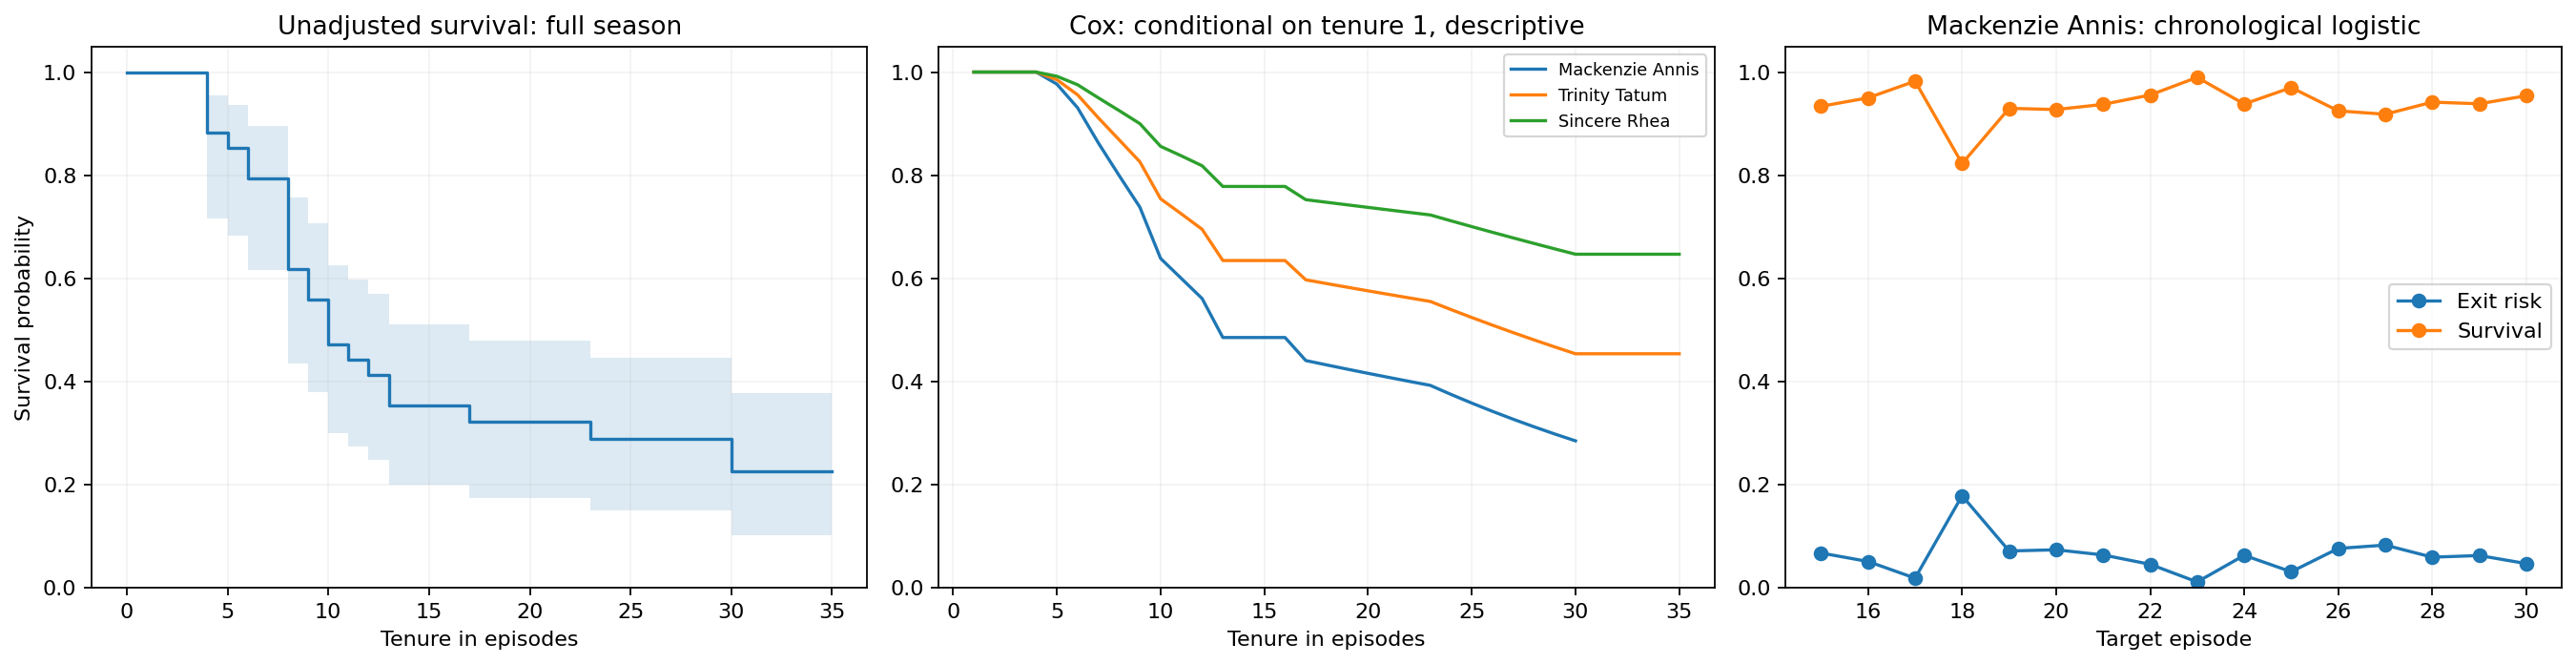

In [ ]:
model_figure, model_axes = plt.subplots(1, 3, figsize=(17, 4.5))

model_axes[0].step(km_survival_probabilities["tenure_episode"], km_survival_probabilities["survival_probability"], where="post", label="Kaplan–Meier")
model_axes[0].fill_between(km_survival_probabilities["tenure_episode"], km_survival_probabilities["survival_probability_lower_0.95"], km_survival_probabilities["survival_probability_upper_0.95"], step="post", alpha=0.15)
model_axes[0].set_title("Unadjusted survival: full season")
model_axes[0].set_xlabel("Tenure in episodes")
model_axes[0].set_ylabel("Survival probability")

example_islanders = ["Mackenzie Annis", "Trinity Tatum", "Sincere Rhea"]
for islander_name in example_islanders:
    islander_curve_rows = cox_survival_probabilities["target_islander"].eq(islander_name)
    islander_curve_rows = islander_curve_rows & cox_survival_probabilities["within_observed_followup"]
    islander_curve = cox_survival_probabilities.loc[islander_curve_rows]
    model_axes[1].plot(islander_curve["tenure_episode"], islander_curve["survival_probability"], label=islander_name)
model_axes[1].set_title("Cox: conditional on tenure 1, descriptive")
model_axes[1].set_xlabel("Tenure in episodes")
model_axes[1].legend(fontsize=8)

logistic_islander_rows = logistic_episode_probabilities["target_islander"].eq(islander_to_inspect)
logistic_islander_predictions = logistic_episode_probabilities.loc[logistic_islander_rows]
model_axes[2].plot(logistic_islander_predictions["target_episode"], logistic_islander_predictions["booted_next_episode_probability"], marker="o", label="Exit risk")
model_axes[2].plot(logistic_islander_predictions["target_episode"], logistic_islander_predictions["survive_next_episode_probability"], marker="o", label="Survival")
model_axes[2].set_title(f"{islander_to_inspect}: chronological logistic")
model_axes[2].set_xlabel("Target episode")
model_axes[2].legend()

for model_axis in model_axes:
    model_axis.set_ylim(0, 1.05)
    model_axis.grid(alpha=0.15)
model_figure.tight_layout()
model_figure_path = project_root / "viz" / "inline_survival_models.png"
model_figure.savefig(model_figure_path, dpi=160, bbox_inches="tight")
plt.show()

## 11. Save probabilities, model details and evaluation

These exports replace only the tables named below. Existing source datasets and older experimental outputs remain unchanged. Each probability table carries model version and estimate type. Save preprocessing and coefficients so the numerical fit can be audited without relying on a hidden function or a pickled model.

In [ ]:
model_configuration = {
    "model_version": model_version,
    "run_time": model_run_time,
    "cox_covariates": cox_covariates,
    "cox_penalty": cox_penalty,
    "cox_landmark_tenure": 1,
    "logistic_covariates": logistic_model_features,
    "logistic_inverse_penalty": logistic_inverse_penalty,
    "minimum_training_events": minimum_training_events,
    "cutoff": "earliest observed next-episode comment; retrospective proxy",
    "event": "final exit; finalists censored",
    "python_version": platform.python_version(),
    "lifelines_version": lifelines.__version__,
    "sklearn_version": sklearn.__version__,
}
model_configuration_json = json.dumps(model_configuration, indent=2)
model_configuration_path = probability_export_directory / "inline_model_configuration.json"
model_configuration_path.write_text(model_configuration_json, encoding="utf-8")
model_configuration_table = pd.DataFrame([{"configuration_json": model_configuration_json}])

model_tables = {
    "km_survival_probabilities": km_survival_probabilities,
    "cox_survival_probabilities": cox_survival_probabilities,
    "cox_model_coefficients": cox_coefficient_summary,
    "cox_model_preprocessing": cox_preprocessing,
    "cox_baseline_cumulative_hazard": cox_baseline_hazard,
    "logistic_episode_probabilities": logistic_episode_probabilities,
    "logistic_model_evaluation": logistic_evaluation,
    "logistic_model_calibration": logistic_calibration,
    "logistic_model_folds": logistic_folds,
    "logistic_model_coefficients": logistic_coefficients,
    "logistic_model_preprocessing": logistic_preprocessing,
    "model_episode_probabilities": model_episode_probabilities,
    "survival_model_configuration": model_configuration_table,
}

with duckdb.connect(str(database_path)) as connection:
    connection.execute("CREATE SCHEMA IF NOT EXISTS dashboard")
    connection.execute("BEGIN TRANSACTION")
    try:
        for table_name, model_dataset in model_tables.items():
            model_dataset["model_version"] = model_version
            model_dataset["model_run_time"] = model_run_time
            connection.register("model_export", model_dataset)
            connection.execute(f"CREATE OR REPLACE TABLE dashboard.{table_name} AS SELECT * FROM model_export")
            saved_dataset = connection.execute(f"SELECT * FROM dashboard.{table_name}").df()
            pd.testing.assert_frame_equal(saved_dataset, model_dataset.reset_index(drop=True), check_dtype=False)
            connection.unregister("model_export")
        connection.execute("COMMIT")
    except Exception:
        connection.execute("ROLLBACK")
        raise

for table_name, model_dataset in model_tables.items():
    csv_path = probability_export_directory / f"{table_name}.csv"
    model_dataset.to_csv(csv_path, index=False, encoding="utf-8")
    print(f"Saved dashboard.{table_name}: {len(model_dataset):,} rows — DuckDB and CSV")

Saved dashboard.km_survival_probabilities: 16 rows — DuckDB and CSV
Saved dashboard.cox_survival_probabilities: 905 rows — DuckDB and CSV
Saved dashboard.cox_model_coefficients: 6 rows — DuckDB and CSV
Saved dashboard.cox_model_preprocessing: 6 rows — DuckDB and CSV
Saved dashboard.cox_baseline_cumulative_hazard: 15 rows — DuckDB and CSV
Saved dashboard.logistic_episode_probabilities: 503 rows — DuckDB and CSV
Saved dashboard.logistic_model_evaluation: 2 rows — DuckDB and CSV
Saved dashboard.logistic_model_calibration: 4 rows — DuckDB and CSV
Saved dashboard.logistic_model_folds: 34 rows — DuckDB and CSV
Saved dashboard.logistic_model_coefficients: 168 rows — DuckDB and CSV
Saved dashboard.logistic_model_preprocessing: 168 rows — DuckDB and CSV
Saved dashboard.model_episode_probabilities: 1,543 rows — DuckDB and CSV
Saved dashboard.survival_model_configuration: 1 rows — DuckDB and CSV


## 12. Diagnose logistic prediction spread

Use only chronological test predictions. A narrow range can come from rare exits, weak covariates, shrinkage, or little within-episode separation. These summaries distinguish variation across contestants in the same episode from variation over time for one contestant. Standard deviations are descriptive, not uncertainty intervals.

In [ ]:
logistic_diagnostics = logistic_episode_probabilities.copy()
has_prediction = logistic_diagnostics["prediction_status"].eq("predicted")
logistic_diagnostics = logistic_diagnostics.loc[has_prediction].copy()
logistic_diagnostics["predicted_exit_percent"] = logistic_diagnostics["booted_next_episode_probability"] * 100

logistic_probability_distribution = logistic_diagnostics["predicted_exit_percent"].describe(percentiles=[0.05, 0.25, 0.50, 0.75, 0.95])
logistic_probability_distribution = logistic_probability_distribution.rename("exit_probability_percent")
logistic_probability_distribution = logistic_probability_distribution.to_frame()

logistic_episode_spread = logistic_diagnostics.groupby("target_episode").agg(
    contestants=("target_islander", "size"),
    actual_exits=("event", "sum"),
    expected_exits=("booted_next_episode_probability", "sum"),
    minimum_percent=("predicted_exit_percent", "min"),
    maximum_percent=("predicted_exit_percent", "max"),
    mean_percent=("predicted_exit_percent", "mean"),
    sd_percentage_points=("predicted_exit_percent", "std"),
)
logistic_episode_spread = logistic_episode_spread.reset_index()
logistic_episode_spread["spread_percentage_points"] = logistic_episode_spread["maximum_percent"] - logistic_episode_spread["minimum_percent"]
logistic_episode_spread["observed_exit_percent"] = 100 * logistic_episode_spread["actual_exits"] / logistic_episode_spread["contestants"]

logistic_islander_spread = logistic_diagnostics.groupby("target_islander").agg(
    predicted_episodes=("target_episode", "size"),
    minimum_percent=("predicted_exit_percent", "min"),
    maximum_percent=("predicted_exit_percent", "max"),
    sd_percentage_points=("predicted_exit_percent", "std"),
)
logistic_islander_spread = logistic_islander_spread.reset_index()
logistic_islander_spread["spread_percentage_points"] = logistic_islander_spread["maximum_percent"] - logistic_islander_spread["minimum_percent"]
logistic_islander_spread = logistic_islander_spread.sort_values("spread_percentage_points", ascending=False)

display(logistic_probability_distribution)
display(logistic_episode_spread)
display(logistic_islander_spread)

,exit_probability_percent
count,314.000000
mean,6.489593
std,4.764079
min,0.610803
5%,0.902063
25%,3.406017
50%,5.256956
75%,8.209246
95%,15.675738
max,27.951403


,target_episode,contestants,actual_exits,expected_exits,minimum_percent,maximum_percent,mean_percent,sd_percentage_points,spread_percentage_points,observed_exit_percent
0,15,20,0,0.593219,1.006319,8.294751,2.966097,2.110196,7.288432,0.000000
1,16,20,0,0.561316,0.889753,5.429898,2.806580,1.720236,4.540146,0.000000
2,17,20,6,0.217058,0.745064,1.859933,1.085290,0.405821,1.114868,30.000000
3,18,21,0,2.928831,8.840247,17.761393,13.946815,2.299895,8.921146,0.000000
4,19,21,1,1.106099,2.617920,7.300022,5.267138,1.479001,4.682102,4.761905
5,20,20,4,1.150322,4.105939,9.109173,5.751608,1.412455,5.003233,20.000000
6,21,18,0,1.319018,4.621266,12.316623,7.327879,2.753508,7.695357,0.000000
7,22,18,0,1.135500,3.228371,12.341876,6.308333,3.185342,9.113506,0.000000
8,23,18,0,0.702948,1.027769,12.979959,3.905265,3.325901,11.952191,0.000000
9,24,18,0,1.347797,4.683013,14.404063,7.487763,3.177039,9.721050,0.000000


,target_islander,predicted_episodes,minimum_percent,maximum_percent,sd_percentage_points,spread_percentage_points
25,Tierra Davis,10,4.493787,27.951403,7.027096,23.457616
5,Carl Lee Schmidt,15,6.900839,25.652315,4.274491,18.751476
0,Alannah Keyser,5,0.831933,17.659811,7.247830,16.827878
18,Mackenzie Annis,16,1.027769,17.761393,3.698773,16.733624
1,Amora Cacheé Robinson,8,2.617920,17.273932,4.572719,14.656012
19,Melanie Moreno,21,0.814493,15.196669,3.175498,14.382176
10,Dylan Wrona,5,12.552530,26.934182,6.071535,14.381652
28,Trinity Tatum,21,1.054078,14.566157,2.966640,13.512078
29,Zacharias Georgiou,21,0.807095,14.155210,2.881509,13.348115
3,Bryce Alakai Dettloff,21,1.463198,14.369345,2.959088,12.906147


## 13. Diagnose logistic ranking and calibration

Global discrimination can be poor because the model misses **when** dumpings occur, **who** leaves within a dumping episode, or both. Within-episode AUC evaluates the second question only in episodes containing both exits and survivors. It is undefined for other episodes. Expected exit counts are sums of individual probabilities; group exits violate independence but not this expectation identity. Reliability bins show descriptive Wilson intervals, which do not account for episode/person clustering.

Observed exit rate: 7.0%
Brier skill vs training-rate baseline: -0.052 (positive is better)


,target_episode,contestants,exits,within_episode_auc
0,17,20,6,0.000000
1,19,21,1,0.500000
2,20,20,4,0.093750
3,25,18,5,0.630769
4,26,14,2,0.750000
5,30,12,4,0.718750


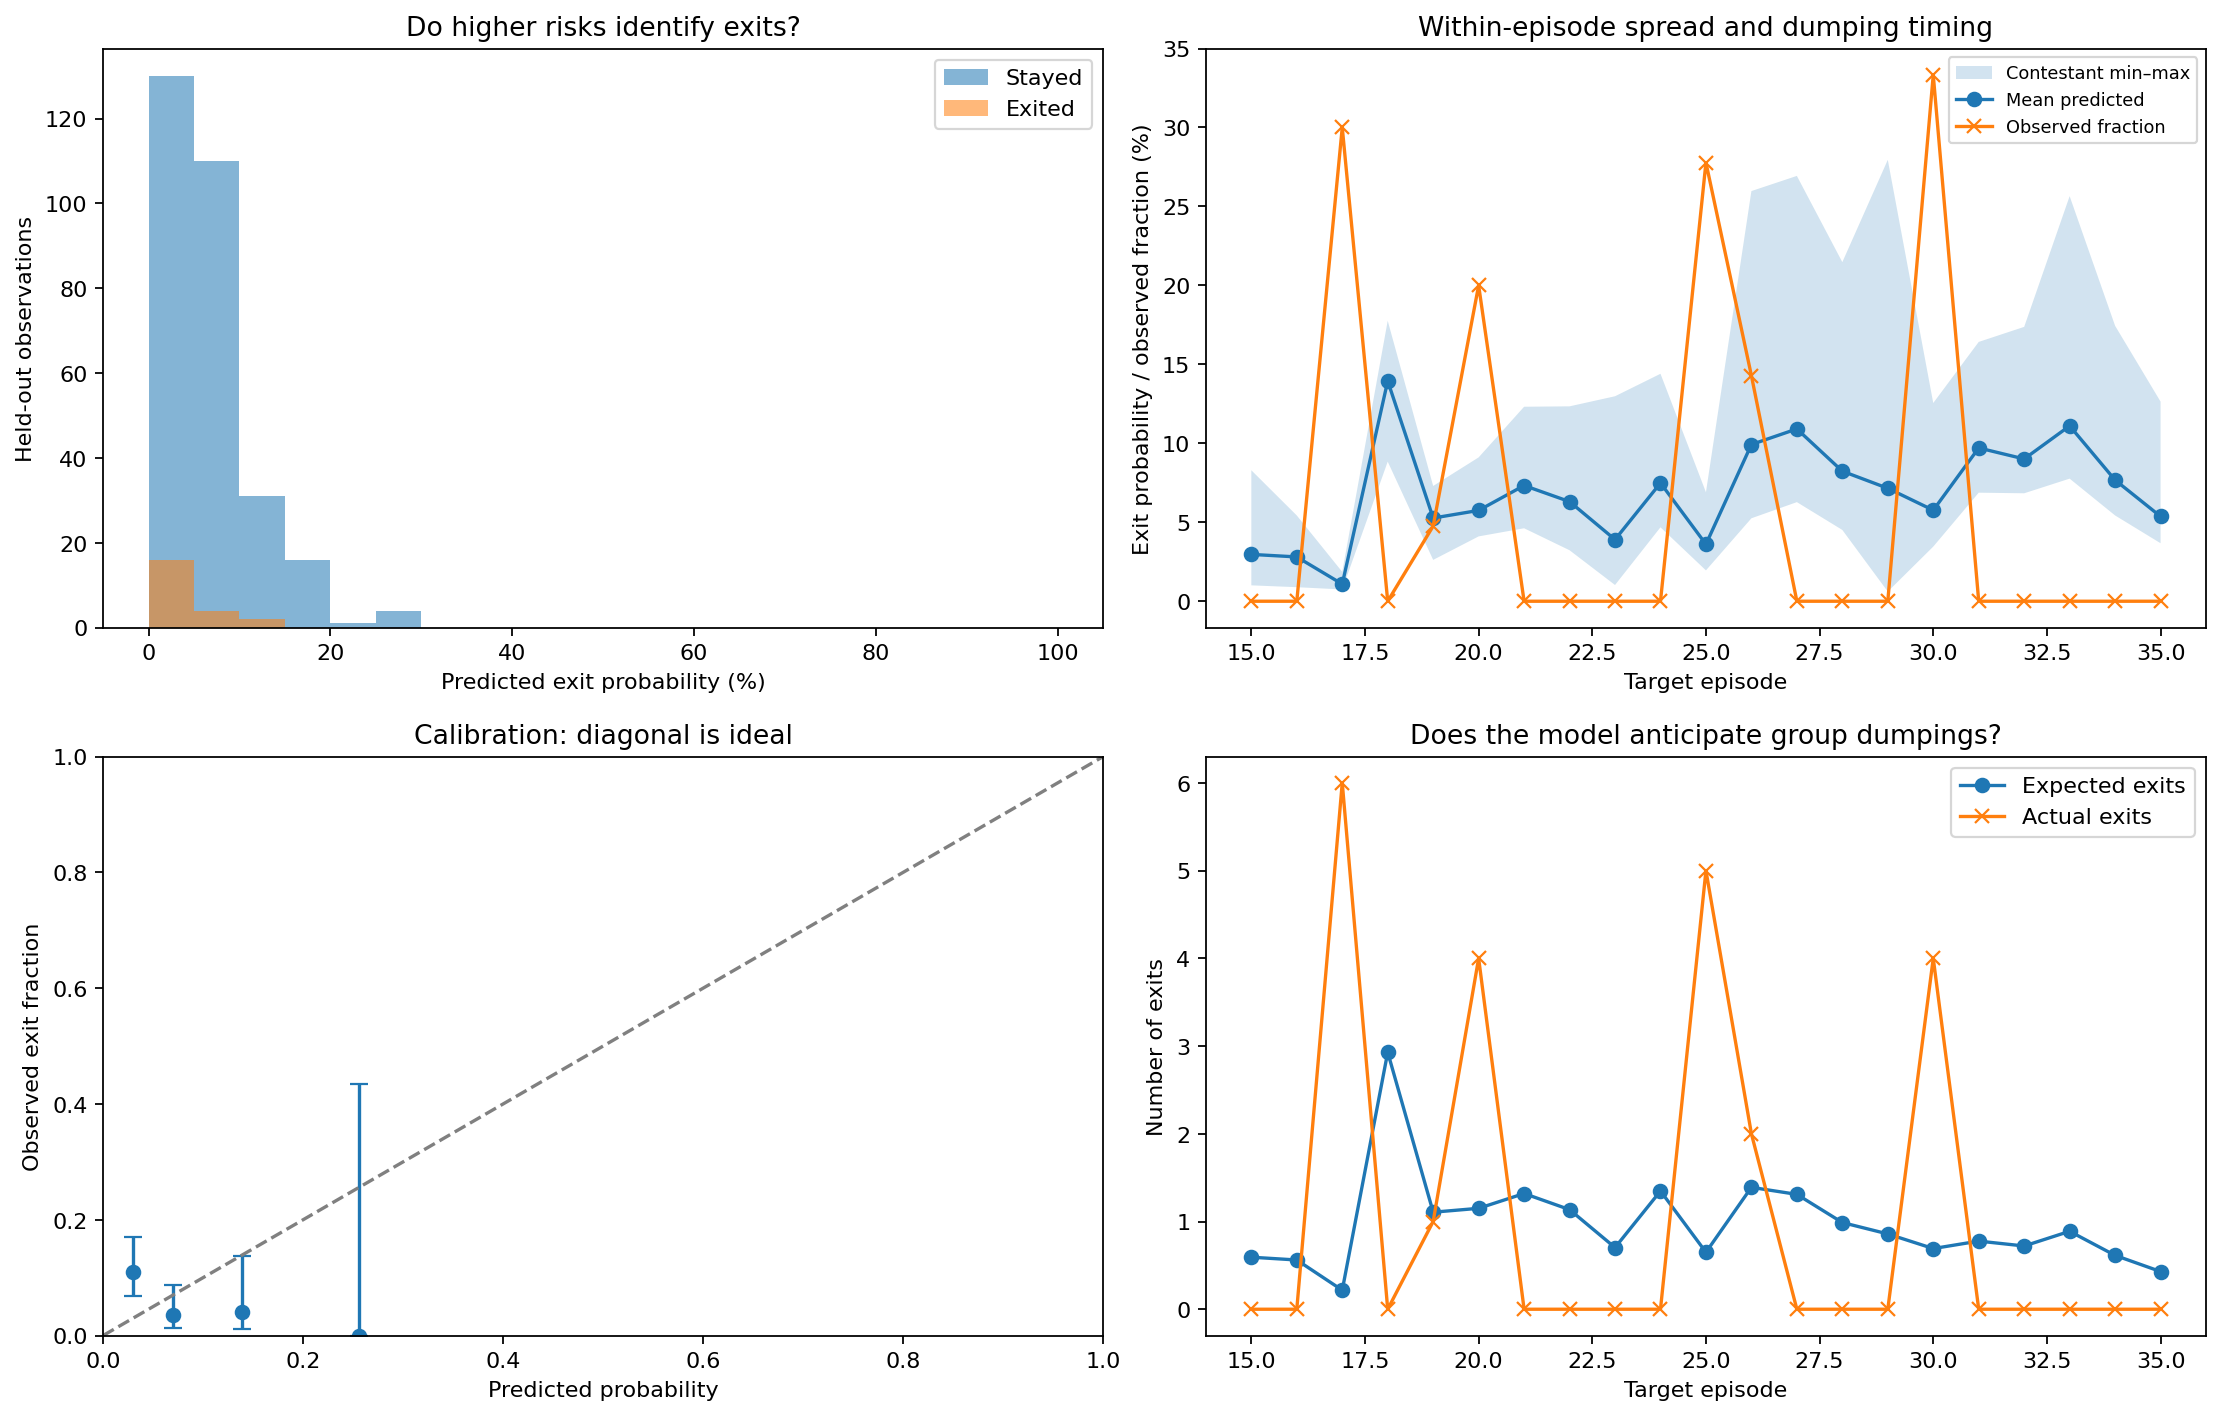

In [ ]:
from statsmodels.stats.proportion import proportion_confint

within_episode_records = []
for episode_number, episode_predictions in logistic_diagnostics.groupby("target_episode"):
    outcome_classes = episode_predictions["event"].nunique()
    if outcome_classes != 2:
        continue
    within_episode_auc = roc_auc_score(episode_predictions["event"], episode_predictions["booted_next_episode_probability"])
    within_episode_records.append({
        "target_episode": episode_number,
        "contestants": len(episode_predictions),
        "exits": int(episode_predictions["event"].sum()),
        "within_episode_auc": within_episode_auc,
    })
logistic_within_episode_ranking = pd.DataFrame(within_episode_records)

observed_event_rate = logistic_diagnostics["event"].mean()
logistic_brier = brier_score_loss(logistic_diagnostics["event"], logistic_diagnostics["booted_next_episode_probability"])
baseline_brier = brier_score_loss(logistic_diagnostics["event"], logistic_diagnostics["baseline_booted_probability"])
logistic_brier_skill = 1 - logistic_brier / baseline_brier
print(f"Observed exit rate: {observed_event_rate:.1%}")
print(f"Brier skill vs training-rate baseline: {logistic_brier_skill:.3f} (positive is better)")
display(logistic_within_episode_ranking)

calibration_diagnostics = logistic_diagnostics.copy()
calibration_diagnostics["probability_bin"] = pd.cut(calibration_diagnostics["booted_next_episode_probability"], bins=[0, .05, .10, .20, .40, .60, 1], include_lowest=True)
calibration_summary = calibration_diagnostics.groupby("probability_bin", observed=True).agg(
    observations=("event", "size"),
    exits=("event", "sum"),
    predicted_probability=("booted_next_episode_probability", "mean"),
    observed_fraction=("event", "mean"),
)
calibration_summary = calibration_summary.reset_index()
calibration_summary["probability_bin"] = calibration_summary["probability_bin"].astype(str)
calibration_lower, calibration_upper = proportion_confint(calibration_summary["exits"], calibration_summary["observations"], method="wilson")
calibration_summary["lower_descriptive_95"] = calibration_lower
calibration_summary["upper_descriptive_95"] = calibration_upper

logistic_diagnostic_figure, logistic_diagnostic_axes = plt.subplots(2, 2, figsize=(14, 9))
for outcome_value, outcome_label in [(0, "Stayed"), (1, "Exited")]:
    outcome_rows = logistic_diagnostics["event"].eq(outcome_value)
    outcome_probabilities = logistic_diagnostics.loc[outcome_rows, "predicted_exit_percent"]
    logistic_diagnostic_axes[0, 0].hist(outcome_probabilities, bins=np.linspace(0, 100, 21), alpha=.55, label=outcome_label)
logistic_diagnostic_axes[0, 0].set_title("Do higher risks identify exits?")
logistic_diagnostic_axes[0, 0].set_xlabel("Predicted exit probability (%)")
logistic_diagnostic_axes[0, 0].set_ylabel("Held-out observations")
logistic_diagnostic_axes[0, 0].legend()

logistic_diagnostic_axes[0, 1].fill_between(logistic_episode_spread["target_episode"], logistic_episode_spread["minimum_percent"], logistic_episode_spread["maximum_percent"], alpha=.2, label="Contestant min–max")
logistic_diagnostic_axes[0, 1].plot(logistic_episode_spread["target_episode"], logistic_episode_spread["mean_percent"], marker="o", label="Mean predicted")
logistic_diagnostic_axes[0, 1].plot(logistic_episode_spread["target_episode"], logistic_episode_spread["observed_exit_percent"], marker="x", label="Observed fraction")
logistic_diagnostic_axes[0, 1].set_title("Within-episode spread and dumping timing")
logistic_diagnostic_axes[0, 1].set_xlabel("Target episode")
logistic_diagnostic_axes[0, 1].set_ylabel("Exit probability / observed fraction (%)")
logistic_diagnostic_axes[0, 1].legend(fontsize=8)

calibration_errors = np.vstack([calibration_summary["observed_fraction"] - calibration_summary["lower_descriptive_95"], calibration_summary["upper_descriptive_95"] - calibration_summary["observed_fraction"]])
logistic_diagnostic_axes[1, 0].errorbar(calibration_summary["predicted_probability"], calibration_summary["observed_fraction"], yerr=calibration_errors, fmt="o", capsize=4)
logistic_diagnostic_axes[1, 0].plot([0, 1], [0, 1], linestyle="--", color="gray")
logistic_diagnostic_axes[1, 0].set_title("Calibration: diagonal is ideal")
logistic_diagnostic_axes[1, 0].set_xlabel("Predicted probability")
logistic_diagnostic_axes[1, 0].set_ylabel("Observed exit fraction")
logistic_diagnostic_axes[1, 0].set_xlim(0, 1)
logistic_diagnostic_axes[1, 0].set_ylim(0, 1)

logistic_diagnostic_axes[1, 1].plot(logistic_episode_spread["target_episode"], logistic_episode_spread["expected_exits"], marker="o", label="Expected exits")
logistic_diagnostic_axes[1, 1].plot(logistic_episode_spread["target_episode"], logistic_episode_spread["actual_exits"], marker="x", label="Actual exits")
logistic_diagnostic_axes[1, 1].set_title("Does the model anticipate group dumpings?")
logistic_diagnostic_axes[1, 1].set_xlabel("Target episode")
logistic_diagnostic_axes[1, 1].set_ylabel("Number of exits")
logistic_diagnostic_axes[1, 1].legend()
logistic_diagnostic_figure.tight_layout()
logistic_diagnostic_figure.savefig(project_root / "viz/logistic_model_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

## 14. Inspect predictors and coefficient stability

The model may assign similar probabilities because inputs are similar or missing, or because the fitted coefficients are small. Cox uses **fixed first-post-entry features**, so later sentiment changes cannot change a contestant's fitted relative hazard. Logistic updates features and refits coefficients over time. Standardized coefficients across folds are not strictly comparable because each fold has a different scaling SD; both standardized and original-unit versions are shown.

In [ ]:
cox_input_diagnostics = cox_raw_features.describe().T
cox_input_diagnostics["missing_count"] = cox_raw_features.isna().sum()
cox_input_diagnostics["unique_nonmissing_values"] = cox_raw_features.nunique()
display(cox_input_diagnostics)

logistic_feature_diagnostics = logistic_feature_dataset.describe().T
logistic_feature_diagnostics["missing_count"] = logistic_feature_dataset.isna().sum()
display(logistic_feature_diagnostics)
display(logistic_feature_dataset.corr())

logistic_coefficient_diagnostics = logistic_coefficients.merge(
    logistic_preprocessing[["target_episode", "feature", "scaling_sd"]],
    on=["target_episode", "feature"],
    validate="one_to_one",
)
logistic_coefficient_diagnostics["original_unit_coefficient"] = logistic_coefficient_diagnostics["standardized_coefficient"] / logistic_coefficient_diagnostics["scaling_sd"]
logistic_coefficient_stability = logistic_coefficient_diagnostics.groupby("feature").agg(
    minimum_standardized_coefficient=("standardized_coefficient", "min"),
    maximum_standardized_coefficient=("standardized_coefficient", "max"),
    mean_standardized_coefficient=("standardized_coefficient", "mean"),
)
logistic_coefficient_stability = logistic_coefficient_stability.reset_index()
logistic_coefficient_stability["changes_sign"] = logistic_coefficient_stability["minimum_standardized_coefficient"].lt(0) & logistic_coefficient_stability["maximum_standardized_coefficient"].gt(0)
display(logistic_coefficient_stability)

,count,mean,std,min,25%,50%,75%,max,missing_count,unique_nonmissing_values
asof_log_comments,34.0,3.280212,2.809373,0.000000,0.000000,4.251547,5.823046,6.844815,0,21
asof_roberta_mean,21.0,-0.086803,0.209970,-0.383610,-0.283800,-0.113341,0.142635,0.227277,13,21
asof_toxicity_mean,21.0,0.102875,0.051064,0.045470,0.067989,0.088069,0.114082,0.249781,13,21
asof_comention_strength_per_comment,21.0,1.293479,0.557432,0.245614,0.930693,1.198813,1.666667,2.913043,13,21
asof_top1_comention_share,21.0,0.398014,0.164691,0.105263,0.275949,0.403561,0.523454,0.738095,13,21


,count,mean,std,min,25%,50%,75%,max,missing_count
feature_episode,503.0,16.773360,8.525117,1.000000,10.000000,17.000000,23.000000,34.000000,0
start,503.0,12.312127,9.513253,1.000000,4.000000,9.000000,19.500000,34.000000,0
asof_log_comments,503.0,4.884200,2.143045,0.000000,4.356380,5.620401,6.330580,7.720018,0
asof_roberta_mean,447.0,-0.248539,0.199491,-0.787488,-0.398015,-0.295133,-0.107105,0.438129,56
asof_toxicity_mean,447.0,0.124934,0.067274,0.000711,0.087065,0.113923,0.150970,0.835847,56
asof_comention_strength_per_comment,447.0,1.664080,0.670128,0.000000,1.209334,1.577896,2.009692,6.600000,56
asof_top1_comention_share,447.0,0.461707,0.161929,0.000000,0.343228,0.451895,0.555556,1.000000,56
missing_discussion,503.0,0.111332,0.314856,0.000000,0.000000,0.000000,0.000000,1.000000,0


,feature_episode,start,asof_log_comments,asof_roberta_mean,asof_toxicity_mean,asof_comention_strength_per_comment,asof_top1_comention_share,missing_discussion
feature_episode,1.000000,0.750168,0.110635,-0.169796,0.181816,0.050914,0.068735,-0.144203
start,0.750168,1.000000,0.346256,-0.242752,0.208192,0.084868,0.033785,-0.322204
asof_log_comments,0.110635,0.346256,1.000000,-0.196802,0.127384,-0.484301,-0.315165,-0.807485
asof_roberta_mean,-0.169796,-0.242752,-0.196802,1.000000,-0.370341,-0.064608,-0.039135,NaN
asof_toxicity_mean,0.181816,0.208192,0.127384,-0.370341,1.000000,0.072886,0.017982,NaN
asof_comention_strength_per_comment,0.050914,0.084868,-0.484301,-0.064608,0.072886,1.000000,0.586635,NaN
asof_top1_comention_share,0.068735,0.033785,-0.315165,-0.039135,0.017982,0.586635,1.000000,NaN
missing_discussion,-0.144203,-0.322204,-0.807485,NaN,NaN,NaN,NaN,1.000000


,feature,minimum_standardized_coefficient,maximum_standardized_coefficient,mean_standardized_coefficient,changes_sign
0,asof_comention_strength_per_comment,-0.471377,-0.114365,-0.261868,False
1,asof_log_comments,-0.116663,0.400216,0.047483,True
2,asof_roberta_mean,-0.164465,0.098567,-0.000281,True
3,asof_top1_comention_share,-0.180978,0.129067,-0.008344,True
4,asof_toxicity_mean,-0.158368,0.064370,-0.015089,True
5,feature_episode,0.220081,0.895228,0.640291,False
6,missing_discussion,-0.171076,0.532728,0.257116,True
7,start,-0.577958,0.163273,-0.276259,True


## 15. Diagnose Cox separation at a common horizon

Comparing Cox curves at different follow-up times confounds duration with prediction. Compare every eligible contestant at the same tenure (10), conditional on reaching tenure 1. These are full-season model-implied curves, even for someone who exited earlier; they are not validated forecasts. Cox proportional hazards enforces constant relative hazard over tenure, so curve shapes can look similar even when levels differ. The apparent C-index is optimistic because it uses the fitting sample.

Apparent Cox concordance: 0.747; training-sample only
Cox common-horizon spread:


,relative_hazard,survival_at_tenure_10
count,34.000000,34.000000
mean,1.195898,0.544189
std,0.645335,0.189763
min,0.277665,0.338811
25%,0.663041,0.338811
50%,0.975859,0.578921
75%,1.930271,0.689513
max,1.930271,0.855826


,target_islander,relative_hazard,survival_at_tenure_10,booted_by_tenure_10
0,Alannah Keyser,1.930271,0.338811,0.661189
31,Trae Taylor,1.930271,0.338811,0.661189
30,Tino Ellis,1.930271,0.338811,0.661189
19,Kyle Greene,1.930271,0.338811,0.661189
17,Keyon Harry,1.930271,0.338811,0.661189
24,Ryan Ten Hulscher,1.930271,0.338811,0.661189
7,Chandlar Wilson,1.930271,0.338811,0.661189
8,Chaten Nehra,1.930271,0.338811,0.661189
10,Corey Sawyer Jr.,1.930271,0.338811,0.661189
23,Ronnie Gunter,1.930271,0.338811,0.661189


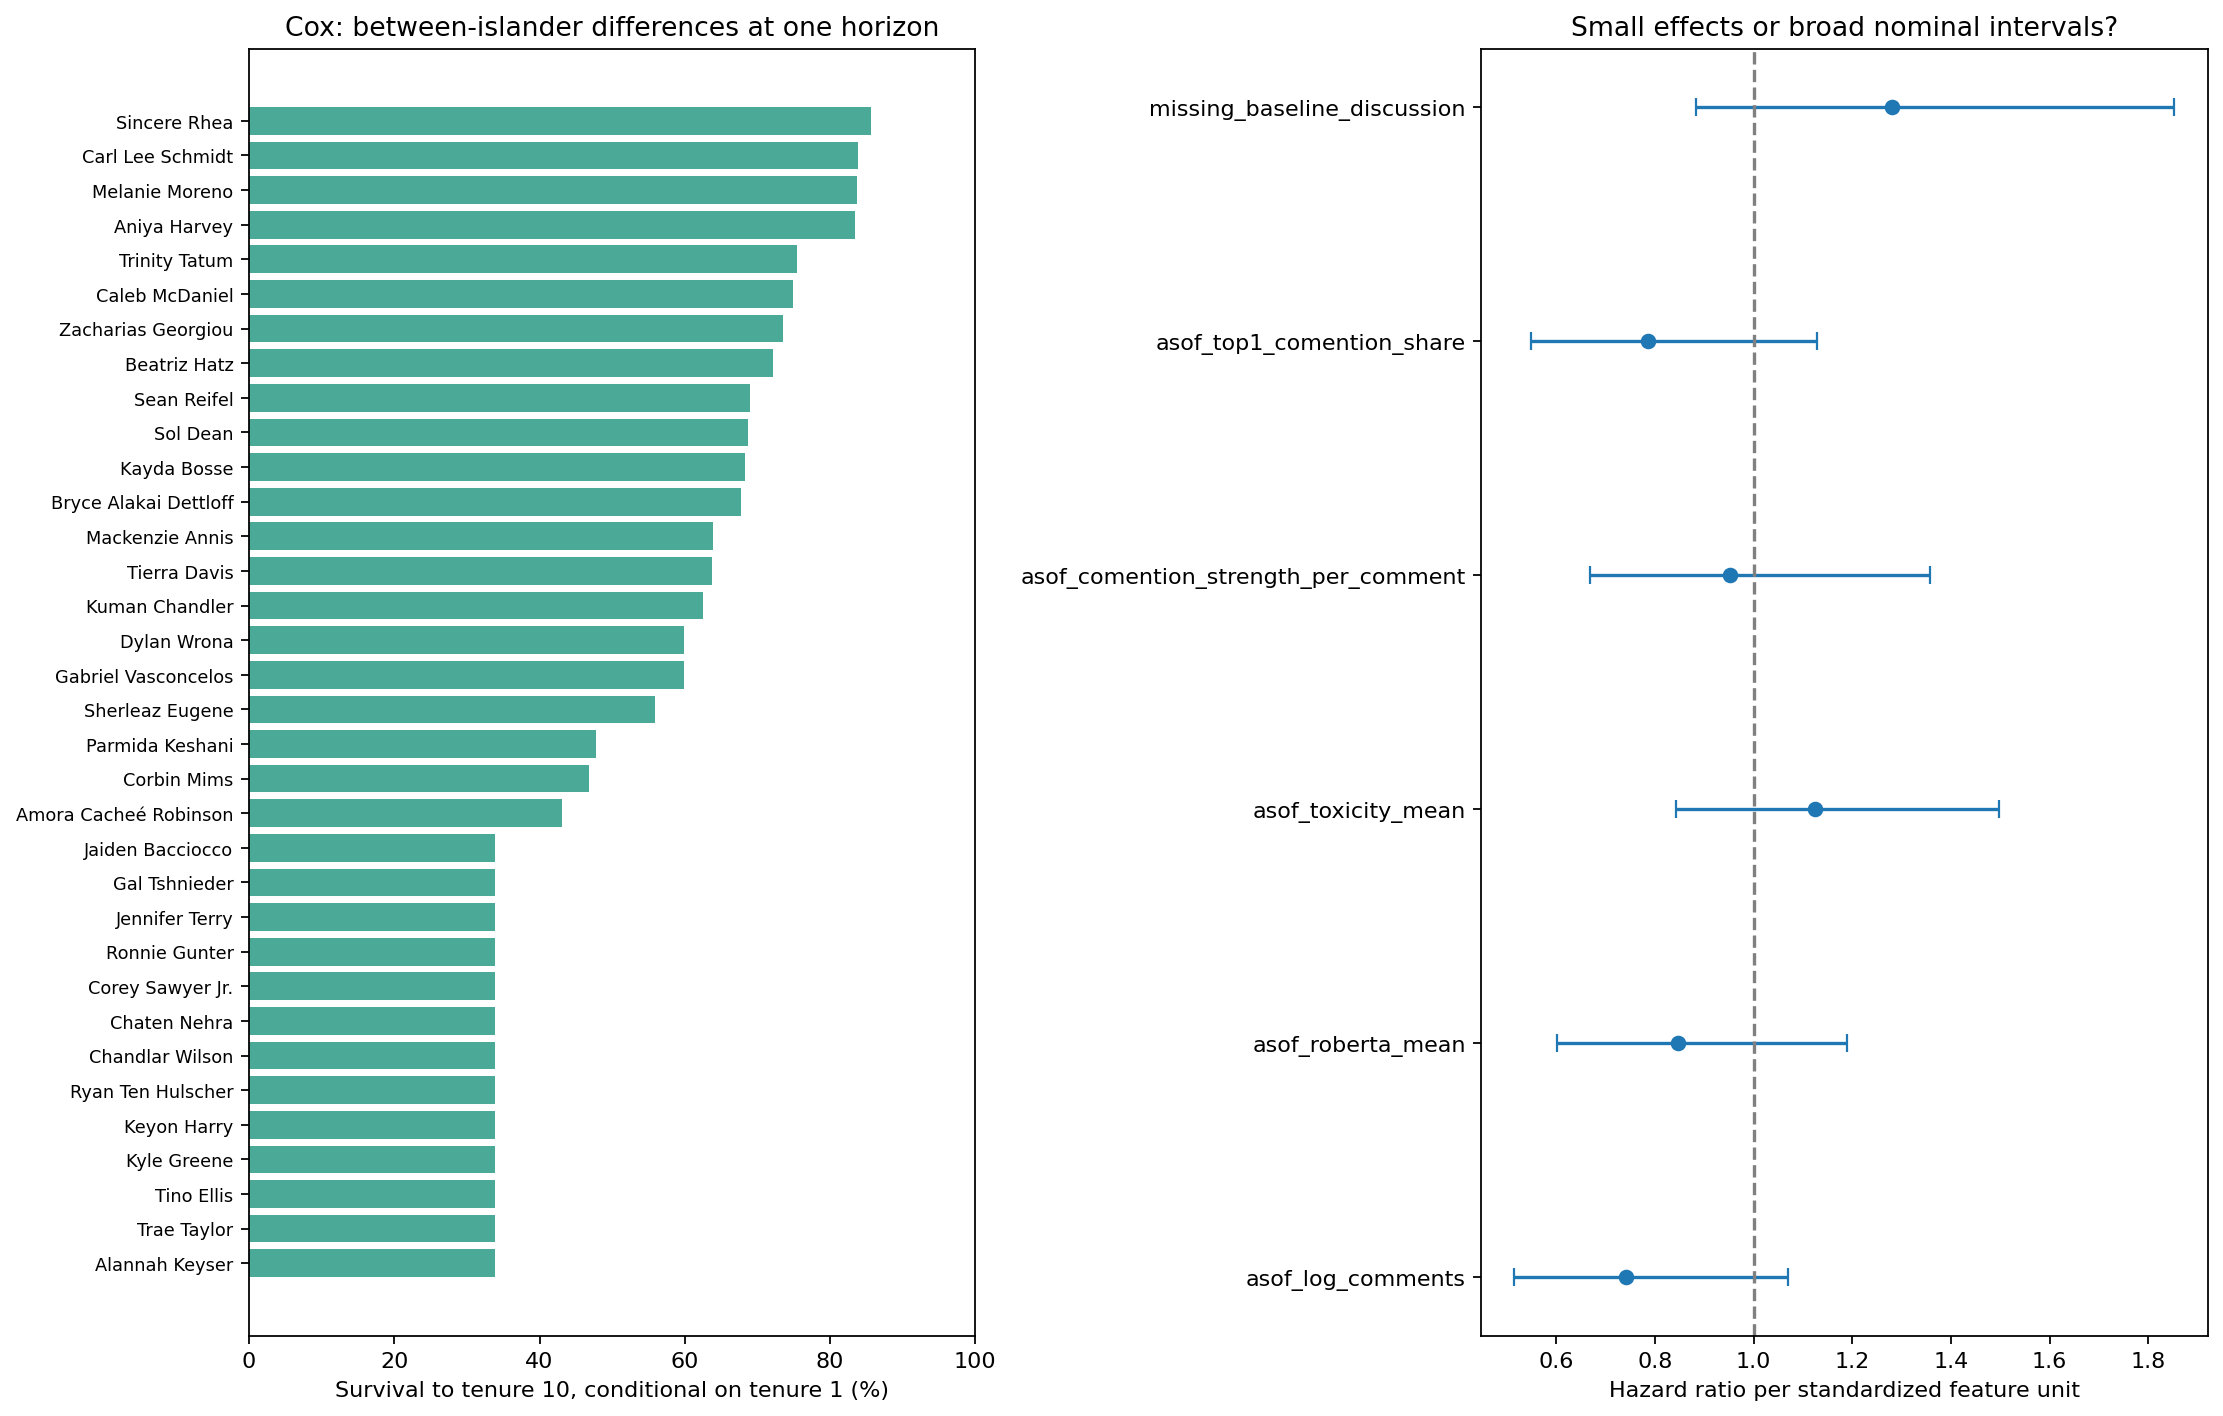

In [ ]:
cox_diagnostic_horizon = 10
cox_risk_diagnostics = cox_model.predict_partial_hazard(cox_scaled_features)
cox_risk_diagnostics = cox_risk_diagnostics.rename("relative_hazard").to_frame()
cox_risk_diagnostics["survival_at_tenure_10"] = cox_conditional_survival.loc[cox_diagnostic_horizon]
cox_risk_diagnostics["booted_by_tenure_10"] = 1 - cox_risk_diagnostics["survival_at_tenure_10"]
cox_risk_diagnostics.index.name = "target_islander"
cox_risk_diagnostics = cox_risk_diagnostics.reset_index()
cox_risk_diagnostics = cox_risk_diagnostics.sort_values("survival_at_tenure_10")

print(f"Apparent Cox concordance: {cox_model.concordance_index_:.3f}; training-sample only")
print("Cox common-horizon spread:")
display(cox_risk_diagnostics[["relative_hazard", "survival_at_tenure_10"]].describe())
display(cox_risk_diagnostics)

cox_diagnostic_figure, cox_diagnostic_axes = plt.subplots(1, 2, figsize=(14, 9))
cox_diagnostic_axes[0].barh(cox_risk_diagnostics["target_islander"], 100 * cox_risk_diagnostics["survival_at_tenure_10"], color="#4aa997")
cox_diagnostic_axes[0].set_xlim(0, 100)
cox_diagnostic_axes[0].set_xlabel("Survival to tenure 10, conditional on tenure 1 (%)")
cox_diagnostic_axes[0].set_title("Cox: between-islander differences at one horizon")
cox_diagnostic_axes[0].tick_params(axis="y", labelsize=8)

coefficient_plot = cox_coefficient_summary.copy()
coefficient_errors = np.vstack([coefficient_plot["exp(coef)"] - coefficient_plot["exp(coef) lower 95%"], coefficient_plot["exp(coef) upper 95%"] - coefficient_plot["exp(coef)"]])
cox_diagnostic_axes[1].errorbar(coefficient_plot["exp(coef)"], coefficient_plot["feature"], xerr=coefficient_errors, fmt="o", capsize=4)
cox_diagnostic_axes[1].axvline(1, linestyle="--", color="gray")
cox_diagnostic_axes[1].set_xlabel("Hazard ratio per standardized feature unit")
cox_diagnostic_axes[1].set_title("Small effects or broad nominal intervals?")
cox_diagnostic_figure.tight_layout()
cox_diagnostic_figure.savefig(project_root / "viz/cox_model_diagnostics.png", dpi=160, bbox_inches="tight")
plt.show()

## 16. Check Cox assumptions and shrinkage sensitivity

Lifelines cannot compute Schoenfeld residuals with an entry column. Here **every landmark entry equals 1**, so we subtract that common landmark from all durations and refit the identical covariate model without delayed entry. We verify that coefficients agree before testing proportional hazards. The test is exploratory, with low power in 34 people and many tied/group exits; a large p-value does not prove the assumption. Sensitivity fits show whether shrinkage drives flat predictions, not which penalty should be selected. They do not replace the primary model.

In [ ]:
from lifelines.statistics import proportional_hazard_test

assert cox_fit_dataset["baseline_entry_time"].eq(1).all()
cox_residual_dataset = cox_fit_dataset.drop(columns=["baseline_entry_time"]).copy()
cox_residual_dataset["duration_episodes"] = cox_residual_dataset["duration_episodes"] - 1
cox_residual_model = CoxPHFitter(penalizer=cox_penalty)
cox_residual_model.fit(cox_residual_dataset, duration_col="duration_episodes", event_col="event_observed")
assert np.allclose(cox_residual_model.params_, cox_model.params_, atol=1e-5)

cox_ph_test = proportional_hazard_test(cox_residual_model, cox_residual_dataset, time_transform="rank")
cox_ph_diagnostics = cox_ph_test.summary.copy()
cox_ph_diagnostics.index.name = "feature"
cox_ph_diagnostics = cox_ph_diagnostics.reset_index()
cox_ph_diagnostics["test_scope"] = "exploratory_common_landmark_rank_test"
display(cox_ph_diagnostics)

cox_sensitivity_records = []
for sensitivity_penalty in [0.10, 0.50, 1.00]:
    sensitivity_model = CoxPHFitter(penalizer=sensitivity_penalty)
    sensitivity_model.fit(cox_fit_dataset, duration_col="duration_episodes", event_col="event_observed", entry_col="baseline_entry_time")
    sensitivity_survival = sensitivity_model.predict_survival_function(cox_scaled_features, times=[1, cox_diagnostic_horizon])
    sensitivity_conditional_survival = sensitivity_survival.loc[cox_diagnostic_horizon] / sensitivity_survival.loc[1]
    cox_sensitivity_records.append({
        "penalty": sensitivity_penalty,
        "tenure_horizon": cox_diagnostic_horizon,
        "minimum_survival": sensitivity_conditional_survival.min(),
        "maximum_survival": sensitivity_conditional_survival.max(),
        "survival_sd": sensitivity_conditional_survival.std(),
        "apparent_concordance": sensitivity_model.concordance_index_,
    })
cox_penalty_sensitivity = pd.DataFrame(cox_sensitivity_records)
display(cox_penalty_sensitivity)

,feature,test_statistic,p,-log2(p),test_scope
0,asof_comention_strength_per_comment,0.043107,0.835524,0.259247,exploratory_common_landmark_rank_test
1,asof_log_comments,0.024401,0.875869,0.191212,exploratory_common_landmark_rank_test
2,asof_roberta_mean,0.084598,0.771160,0.374898,exploratory_common_landmark_rank_test
3,asof_top1_comention_share,0.327896,0.566901,0.818832,exploratory_common_landmark_rank_test
4,asof_toxicity_mean,2.314398,0.128181,2.963747,exploratory_common_landmark_rank_test
5,missing_baseline_discussion,0.186077,0.666202,0.585968,exploratory_common_landmark_rank_test


,penalty,tenure_horizon,minimum_survival,maximum_survival,survival_sd,apparent_concordance
0,0.1,10,0.293424,0.948735,0.244623,0.750499
1,0.5,10,0.338811,0.855826,0.189763,0.746507
2,1.0,10,0.379822,0.790853,0.149623,0.746507


## 17. Save diagnostics without changing the primary models

These diagnostics help decide whether the problem is limited signal, missing data, inappropriate model structure, or poor timing information. Do not widen probability ranges just for appearance. Do not choose penalties using these test outcomes and continue calling the resulting performance held out. Primary model probabilities remain unchanged.

In [ ]:
model_diagnostic_tables = {
    "logistic_probability_distribution": logistic_probability_distribution.reset_index(),
    "logistic_episode_spread": logistic_episode_spread,
    "logistic_islander_spread": logistic_islander_spread,
    "logistic_within_episode_ranking": logistic_within_episode_ranking,
    "logistic_calibration_diagnostics": calibration_summary,
    "logistic_coefficient_stability": logistic_coefficient_stability,
    "cox_risk_diagnostics": cox_risk_diagnostics,
    "cox_ph_diagnostics": cox_ph_diagnostics,
    "cox_penalty_sensitivity": cox_penalty_sensitivity,
}

with duckdb.connect(str(database_path)) as connection:
    connection.execute("BEGIN TRANSACTION")
    try:
        for diagnostic_name, diagnostic_dataset in model_diagnostic_tables.items():
            diagnostic_dataset["model_version"] = model_version
            diagnostic_dataset["model_run_time"] = model_run_time
            connection.register("diagnostic_export", diagnostic_dataset)
            connection.execute(f"CREATE OR REPLACE TABLE dashboard.{diagnostic_name} AS SELECT * FROM diagnostic_export")
            connection.unregister("diagnostic_export")
        connection.execute("COMMIT")
    except Exception:
        connection.execute("ROLLBACK")
        raise

for diagnostic_name, diagnostic_dataset in model_diagnostic_tables.items():
    diagnostic_path = probability_export_directory / f"{diagnostic_name}.csv"
    diagnostic_dataset.to_csv(diagnostic_path, index=False)
print("Saved model diagnostics to DuckDB and CSV; primary probabilities were not changed.")

Saved model diagnostics to DuckDB and CSV; primary probabilities were not changed.


## 18. Prepare episode-updated Cox covariates

This **additional** Cox model updates each islander's predictors every episode. Episode 15 uses episode 14 discussion, episode 16 uses episode 15, and so on. The earlier fixed-baseline Cox model remains available for comparison.

Use **broadcast episode** as the time scale: each row covers `(target_episode - 1, target_episode]`. This compares islanders at risk during the same episode, rather than comparing someone in episode 5 with a later entrant in episode 25. Entry intervals are excluded because there is no preceding in-study discussion. Survival is conditional on reaching the first modeled interval; temporary absences remain a limitation of the existing risk-set data.

We fit a full-season descriptive model, then separately refit using earlier outcomes for chronological relative-risk scores. Lagging covariates does not, by itself, turn a full-season fit into an out-of-time forecast. [Lifelines time-varying Cox documentation](https://lifelines.readthedocs.io/en/stable/Time%20varying%20survival%20regression.html).

In [ ]:
# 1. Load the saved intervals. This section can run without refitting earlier models.
from pathlib import Path
import json
import warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from lifelines import CoxTimeVaryingFitter
from lifelines.exceptions import ConvergenceError
from sklearn.preprocessing import StandardScaler

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

database_path = project_root / "data" / "love_island_reddit.duckdb"
with duckdb.connect(str(database_path), read_only=True) as connection:
    time_varying_source = connection.execute("SELECT * FROM dashboard.survival_intervals").df()

# One row describes the next episode using only the previous episode's covariates.
eligible_intervals = time_varying_source["prediction_eligible"].eq(True)
time_varying_intervals = time_varying_source.loc[eligible_intervals].copy()
time_varying_intervals = time_varying_intervals.sort_values(["target_islander", "target_episode"])
time_varying_intervals = time_varying_intervals.reset_index(drop=True)

time_varying_covariates = [
    "asof_log_comments",
    "asof_roberta_mean",
    "asof_toxicity_mean",
    "asof_comention_strength_per_comment",
    "asof_top1_comention_share",
]
time_varying_penalty = 0.50
time_varying_minimum_training_events = 3
time_varying_model_version = "cox_time_varying_calendar_v1"
time_varying_run_time = pd.Timestamp.now(tz="UTC").isoformat()

# Keep outcome and timing columns separate from predictors.
assert not time_varying_intervals.duplicated(["target_islander", "target_episode"]).any()
assert time_varying_intervals["feature_episode"].eq(time_varying_intervals["target_episode"] - 1).all()
assert time_varying_intervals["calendar_stop"].eq(time_varying_intervals["target_episode"]).all()
assert time_varying_intervals["calendar_start"].eq(time_varying_intervals["feature_episode"]).all()
assert time_varying_intervals["calendar_stop"].gt(time_varying_intervals["calendar_start"]).all()
known_timestamps = time_varying_intervals["asof_latest_timestamp"].notna()
latest_timestamps = time_varying_intervals.loc[known_timestamps, "asof_latest_timestamp"]
interval_cutoffs = time_varying_intervals.loc[known_timestamps, "cutoff_proxy"]
assert latest_timestamps.lt(interval_cutoffs).all()

# Each person contributes a contiguous history and at most one terminal event.
for islander_name, islander_intervals in time_varying_intervals.groupby("target_islander"):
    episode_steps = islander_intervals["target_episode"].diff().dropna()
    assert episode_steps.eq(1).all()
    assert islander_intervals["event"].sum() <= 1
    if islander_intervals["event"].sum() == 1:
        assert islander_intervals["event"].iloc[-1] == 1

print(f"{len(time_varying_intervals)} intervals; {time_varying_intervals['target_islander'].nunique()} islanders; {time_varying_intervals['event'].sum()} final exits.")
preview_columns = ["target_islander", "feature_episode", "target_episode", "calendar_start", "calendar_stop", "event"]
preview_columns = preview_columns + time_varying_covariates
preview_islander = time_varying_intervals["target_islander"].eq("Mackenzie Annis")
display(time_varying_intervals.loc[preview_islander, preview_columns].head(10))

503 intervals; 34 islanders; 26 final exits.


,target_islander,feature_episode,target_episode,calendar_start,calendar_stop,event,asof_log_comments,asof_roberta_mean,asof_toxicity_mean,asof_comention_strength_per_comment,asof_top1_comention_share
283,Mackenzie Annis,1,2,1,2,0,6.514713,-0.153613,0.082150,0.793769,0.267062
284,Mackenzie Annis,2,3,2,3,0,6.122493,-0.212092,0.084135,0.991209,0.252747
285,Mackenzie Annis,3,4,3,4,0,6.508769,-0.313553,0.100657,1.055224,0.191045
286,Mackenzie Annis,4,5,4,5,0,6.413459,-0.247449,0.084908,1.889984,0.454844
287,Mackenzie Annis,5,6,5,6,0,6.458338,-0.282284,0.111862,1.248038,0.343799
288,Mackenzie Annis,6,7,6,7,0,6.023448,-0.199712,0.114953,0.800971,0.152913
289,Mackenzie Annis,7,8,7,8,0,6.246107,-0.199091,0.087403,1.396117,0.254369
290,Mackenzie Annis,8,9,8,9,0,6.561031,-0.413803,0.113453,1.322946,0.437677
291,Mackenzie Annis,9,10,9,10,0,5.517453,-0.292335,0.120528,1.096774,0.270161
292,Mackenzie Annis,10,11,10,11,0,1.098612,0.035007,0.835847,4.000000,1.000000


## 19. Fit the time-varying Cox model

Predictors are constant within one episode interval and update at the next interval. Median imputation, scaling and coefficients here use the full season because this fit is descriptive. Missing discussion is retained with an indicator; it is not silently removed.

Regularization stabilizes the fit but does not establish validity. Multiple rows per islander do not create additional independent contestants. Coefficients are still assumed constant over time: **time-varying covariates do not automatically fix non-proportional effects**. Interdependent dumpings and the small sample limit inferential interpretation; the displayed intervals are nominal model-based intervals, not cluster-adjusted evidence.

In [ ]:
# 2. Prepare predictors for the descriptive full-season fit.
time_varying_raw_features = time_varying_intervals[time_varying_covariates].copy()
time_varying_medians = time_varying_raw_features.median()
time_varying_medians = time_varying_medians.fillna(0)
time_varying_prepared_features = time_varying_raw_features.fillna(time_varying_medians)
missing_discussion = time_varying_raw_features["asof_roberta_mean"].isna()
time_varying_prepared_features["missing_discussion"] = missing_discussion.astype(int)
feature_spread = time_varying_prepared_features.std(ddof=0)
variable_features = feature_spread.gt(0)
time_varying_feature_names = feature_spread.index[variable_features].tolist()
time_varying_prepared_features = time_varying_prepared_features[time_varying_feature_names]

time_varying_scaler = StandardScaler()
scaled_features = time_varying_scaler.fit_transform(time_varying_prepared_features)
time_varying_scaled_features = pd.DataFrame(scaled_features, columns=time_varying_feature_names)
time_varying_fit_dataset = time_varying_scaled_features.copy()
time_varying_fit_dataset["target_islander"] = time_varying_intervals["target_islander"]
time_varying_fit_dataset["interval_start"] = time_varying_intervals["calendar_start"]
time_varying_fit_dataset["interval_stop"] = time_varying_intervals["calendar_stop"]
time_varying_fit_dataset["event"] = time_varying_intervals["event"]

time_varying_cox_model = CoxTimeVaryingFitter(penalizer=time_varying_penalty)
time_varying_cox_model.fit(
    time_varying_fit_dataset,
    id_col="target_islander",
    event_col="event",
    start_col="interval_start",
    stop_col="interval_stop",
    show_progress=False,
)

time_varying_coefficients = time_varying_cox_model.summary.copy()
time_varying_coefficients.index.name = "feature"
time_varying_coefficients = time_varying_coefficients.reset_index()
time_varying_preprocessing = pd.DataFrame({"feature": time_varying_feature_names})
time_varying_preprocessing["imputation_value"] = time_varying_preprocessing["feature"].map(time_varying_medians)
time_varying_preprocessing["scaling_mean"] = time_varying_scaler.mean_
time_varying_preprocessing["scaling_sd"] = time_varying_scaler.scale_
coefficient_columns = ["feature", "coef", "exp(coef)", "exp(coef) lower 95%", "exp(coef) upper 95%"]
display(time_varying_coefficients[coefficient_columns])

,feature,coef,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%
0,asof_log_comments,-0.026025,0.974310,0.863105,1.099844
1,asof_roberta_mean,0.010770,1.010828,0.897315,1.138701
2,asof_toxicity_mean,0.004758,1.004770,0.890364,1.133876
3,asof_comention_strength_per_comment,-0.021486,0.978743,0.867748,1.103936
4,asof_top1_comention_share,-0.019155,0.981027,0.871253,1.104633
5,missing_discussion,0.043812,1.044786,0.926969,1.177577


## 20. Calculate survival along the observed covariate history

For each interval, multiply that episode's baseline cumulative-hazard increment by the islander's updated relative hazard. Conditional interval survival is `exp(-interval_hazard)`; cumulative survival is `exp(-sum(interval_hazard))` from the first modeled interval.

These are **full-season descriptive fitted estimates along observed histories**, not historical forecasts or a causal survival curve. The baseline hazard uses the season's exits, so episodes with no observed exits have zero fitted increments. Do not interpret that as advance knowledge that nobody could leave. We do not extrapolate beyond observed follow-up or invent future sentiment values.

In [ ]:
# 3. Accumulate hazard using the updated predictors in each observed interval.
baseline_cumulative_hazard = time_varying_cox_model.baseline_cumulative_hazard_.iloc[:, 0]
last_episode = int(time_varying_intervals["target_episode"].max())
episode_grid = pd.Index(range(0, last_episode + 1), name="target_episode")
baseline_cumulative_hazard = baseline_cumulative_hazard.reindex(episode_grid)
baseline_cumulative_hazard = baseline_cumulative_hazard.ffill()
baseline_cumulative_hazard = baseline_cumulative_hazard.fillna(0)
baseline_hazard_increments = baseline_cumulative_hazard.diff()
baseline_hazard_increments = baseline_hazard_increments.fillna(0)
assert baseline_hazard_increments.ge(0).all()

time_varying_baseline_hazard = baseline_cumulative_hazard.rename("baseline_cumulative_hazard").to_frame()
time_varying_baseline_hazard["baseline_hazard_increment"] = baseline_hazard_increments
time_varying_baseline_hazard = time_varying_baseline_hazard.reset_index()

result_columns = ["target_islander", "feature_episode", "target_episode", "calendar_start", "calendar_stop", "event", "cutoff_proxy", "asof_latest_timestamp"]
time_varying_probabilities = time_varying_intervals[result_columns].copy()
relative_hazards = time_varying_cox_model.predict_partial_hazard(time_varying_scaled_features)
time_varying_probabilities["relative_hazard"] = relative_hazards.to_numpy()
time_varying_probabilities["baseline_hazard_increment"] = time_varying_probabilities["target_episode"].map(baseline_hazard_increments)
time_varying_probabilities["interval_hazard"] = time_varying_probabilities["baseline_hazard_increment"] * time_varying_probabilities["relative_hazard"]
time_varying_probabilities["survive_next_episode_probability"] = np.exp(-time_varying_probabilities["interval_hazard"])
time_varying_probabilities["booted_next_episode_probability"] = 1 - time_varying_probabilities["survive_next_episode_probability"]
time_varying_probabilities["cumulative_hazard"] = time_varying_probabilities.groupby("target_islander")["interval_hazard"].cumsum()
time_varying_probabilities["survival_probability"] = np.exp(-time_varying_probabilities["cumulative_hazard"])
time_varying_probabilities["conditional_from_episode"] = time_varying_probabilities.groupby("target_islander")["feature_episode"].transform("min")
time_varying_probabilities["estimate_type"] = "full_season_time_varying_observed_path_descriptive"
time_varying_probabilities["model"] = "cox_time_varying"

probability_columns = ["survival_probability", "survive_next_episode_probability", "booted_next_episode_probability"]
for probability_column in probability_columns:
    assert time_varying_probabilities[probability_column].between(0, 1).all()
probability_sum = time_varying_probabilities["survive_next_episode_probability"] + time_varying_probabilities["booted_next_episode_probability"]
assert np.allclose(probability_sum, 1)
survival_changes = time_varying_probabilities.groupby("target_islander")["survival_probability"].diff()
assert survival_changes.dropna().le(1e-10).all()
product_survival = time_varying_probabilities.groupby("target_islander")["survive_next_episode_probability"].cumprod()
assert np.allclose(product_survival, time_varying_probabilities["survival_probability"])
display(time_varying_probabilities.head())

,target_islander,feature_episode,target_episode,calendar_start,calendar_stop,event,cutoff_proxy,asof_latest_timestamp,relative_hazard,baseline_hazard_increment,interval_hazard,survive_next_episode_probability,booted_next_episode_probability,cumulative_hazard,survival_probability,conditional_from_episode,estimate_type,model
0,Alannah Keyser,10,11,10,11,0,2026-06-14 17:30:04,NaT,1.201721,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,10,full_season_time_varying_observed_path_descriptive,cox_time_varying
1,Alannah Keyser,11,12,11,12,0,2026-06-15 17:29:10,NaT,1.201721,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,10,full_season_time_varying_observed_path_descriptive,cox_time_varying
2,Alannah Keyser,12,13,12,13,0,2026-06-16 17:20:09,NaT,1.201721,0.000000,0.000000,1.000000,0.000000,0.000000,1.000000,10,full_season_time_varying_observed_path_descriptive,cox_time_varying
3,Alannah Keyser,13,14,13,14,0,2026-06-18 17:20:40,NaT,1.201721,0.087864,0.105588,0.899796,0.100204,0.105588,0.899796,10,full_season_time_varying_observed_path_descriptive,cox_time_varying
4,Alannah Keyser,14,15,14,15,0,2026-06-19 17:19:46,NaT,1.201721,0.000000,0.000000,1.000000,0.000000,0.105588,0.899796,10,full_season_time_varying_observed_path_descriptive,cox_time_varying


## 21. Refit chronologically for next-episode relative risk

For target episode k, fit only intervals whose outcomes are known through k−1. Preprocessing also uses training rows only. Ongoing contestants are administratively censored at the training cutoff; their later outcome is not used.

Save updated **relative hazards**, not unvalidated next-episode probabilities. With calendar time, a training-only nonparametric Cox baseline ends before the next episode. Extending its cumulative hazard flat would incorrectly produce zero exit probability. Absolute forecasts require a separately justified extrapolation model; the existing chronological logistic model supplies probabilities instead.

Relative hazard is centered on each training fit and is best compared **within the same target episode**, not as an absolute scale across different fits. Early episodes remain unavailable until at least three exits have been observed.

Any convergence or separation warnings are retained in the fold table. A successful fit with a warning is still exploratory; regularization does not remove the underlying data limitation.

In [ ]:
# 4. Refit on earlier episodes only, including training-only imputation and scaling.
chronological_columns = ["target_islander", "feature_episode", "target_episode", "event", "cutoff_proxy"]
chronological_cox_risk = time_varying_intervals[chronological_columns].copy()
chronological_cox_risk["relative_hazard"] = np.nan
chronological_cox_risk["training_last_outcome_episode"] = np.nan
chronological_cox_risk["prediction_status"] = "warmup_no_prediction"
chronological_cox_risk["estimate_type"] = "chronological_relative_hazard_not_probability"
chronological_fold_records = []
chronological_coefficient_tables = []
chronological_preprocessing_tables = []
prediction_episodes = sorted(time_varying_intervals["target_episode"].unique())

for target_episode in prediction_episodes:
    training_mask = time_varying_intervals["target_episode"].lt(target_episode)
    testing_mask = time_varying_intervals["target_episode"].eq(target_episode)
    training_intervals = time_varying_intervals.loc[training_mask].copy()
    testing_intervals = time_varying_intervals.loc[testing_mask].copy()
    training_event_count = int(training_intervals["event"].sum())
    fold_record = {"target_episode": int(target_episode), "training_rows": len(training_intervals), "training_events": training_event_count, "test_rows": len(testing_intervals), "warning_count": 0, "warnings": ""}
    if training_event_count < time_varying_minimum_training_events:
        fold_record["status"] = "warmup_no_prediction"
        chronological_fold_records.append(fold_record)
        continue

    training_features = training_intervals[time_varying_covariates].copy()
    testing_features = testing_intervals[time_varying_covariates].copy()
    training_medians = training_features.median()
    training_medians = training_medians.fillna(0)
    prepared_training = training_features.fillna(training_medians)
    prepared_testing = testing_features.fillna(training_medians)
    prepared_training["missing_discussion"] = training_features["asof_roberta_mean"].isna().astype(int)
    prepared_testing["missing_discussion"] = testing_features["asof_roberta_mean"].isna().astype(int)
    training_spread = prepared_training.std(ddof=0)
    retained_features = training_spread.index[training_spread.gt(0)].tolist()
    prepared_training = prepared_training[retained_features]
    prepared_testing = prepared_testing[retained_features]
    fold_scaler = StandardScaler()
    scaled_training_values = fold_scaler.fit_transform(prepared_training)
    scaled_testing_values = fold_scaler.transform(prepared_testing)
    scaled_training = pd.DataFrame(scaled_training_values, index=training_intervals.index, columns=retained_features)
    scaled_testing = pd.DataFrame(scaled_testing_values, index=testing_intervals.index, columns=retained_features)
    fold_dataset = scaled_training.copy()
    fold_dataset["target_islander"] = training_intervals["target_islander"]
    fold_dataset["interval_start"] = training_intervals["calendar_start"]
    fold_dataset["interval_stop"] = training_intervals["calendar_stop"]
    fold_dataset["event"] = training_intervals["event"]
    fold_model = CoxTimeVaryingFitter(penalizer=time_varying_penalty)
    try:
        with warnings.catch_warnings(record=True) as fit_warnings:
            warnings.simplefilter("always")
            fold_model.fit(fold_dataset, id_col="target_islander", event_col="event", start_col="interval_start", stop_col="interval_stop")
        warning_messages = []
        for fit_warning in fit_warnings:
            warning_messages.append(str(fit_warning.message))
        fold_record["warning_count"] = len(warning_messages)
        fold_record["warnings"] = " | ".join(warning_messages)
    except ConvergenceError as error:
        fold_record["status"] = "fit_failed"
        fold_record["error"] = str(error)
        chronological_cox_risk.loc[testing_mask, "prediction_status"] = "fit_failed"
        chronological_fold_records.append(fold_record)
        continue

    fold_risk = fold_model.predict_partial_hazard(scaled_testing)
    training_last_episode = int(training_intervals["target_episode"].max())
    chronological_cox_risk.loc[testing_mask, "relative_hazard"] = fold_risk.to_numpy()
    chronological_cox_risk.loc[testing_mask, "training_last_outcome_episode"] = training_last_episode
    chronological_cox_risk.loc[testing_mask, "prediction_status"] = "predicted_relative_risk"
    fold_record["training_last_outcome_episode"] = training_last_episode
    fold_record["status"] = "predicted_relative_risk"
    chronological_fold_records.append(fold_record)
    fold_coefficients = fold_model.params_.rename("coefficient").rename_axis("feature").reset_index()
    fold_coefficients["target_episode"] = int(target_episode)
    chronological_coefficient_tables.append(fold_coefficients)
    fold_preprocessing = pd.DataFrame({"feature": retained_features})
    fold_preprocessing["target_episode"] = int(target_episode)
    fold_preprocessing["imputation_value"] = fold_preprocessing["feature"].map(training_medians)
    fold_preprocessing["scaling_mean"] = fold_scaler.mean_
    fold_preprocessing["scaling_sd"] = fold_scaler.scale_
    chronological_preprocessing_tables.append(fold_preprocessing)

chronological_cox_folds = pd.DataFrame(chronological_fold_records)
chronological_cox_coefficients = pd.concat(chronological_coefficient_tables, ignore_index=True)
chronological_cox_preprocessing = pd.concat(chronological_preprocessing_tables, ignore_index=True)
predicted_risk_rows = chronological_cox_risk["prediction_status"].eq("predicted_relative_risk")
training_last_episodes = chronological_cox_risk.loc[predicted_risk_rows, "training_last_outcome_episode"]
target_episodes = chronological_cox_risk.loc[predicted_risk_rows, "target_episode"]
assert training_last_episodes.lt(target_episodes).all()
assert chronological_cox_risk.loc[predicted_risk_rows, "relative_hazard"].gt(0).all()
assert np.isfinite(chronological_cox_risk.loc[predicted_risk_rows, "relative_hazard"]).all()
fold_preview_columns = ["target_episode", "training_rows", "training_events", "status", "warning_count"]
display(chronological_cox_folds[fold_preview_columns])
warning_folds = chronological_cox_folds["warning_count"].fillna(0).gt(0)
print(f"{warning_folds.sum()} chronological fits emitted warnings; details are retained in cox_time_varying_folds.")

3 chronological fits emitted warnings; details are retained in cox_time_varying_folds.


,target_episode,training_rows,training_events,status,warning_count
0,2,0,0,warmup_no_prediction,0
1,3,10,0,warmup_no_prediction,0
2,4,20,0,warmup_no_prediction,0
3,5,33,0,warmup_no_prediction,0
4,6,46,0,warmup_no_prediction,0
5,7,59,1,warmup_no_prediction,0
6,8,71,1,warmup_no_prediction,0
7,9,83,1,warmup_no_prediction,0
8,10,95,1,warmup_no_prediction,0
9,11,107,2,warmup_no_prediction,0


## 22. Inspect how the updated Cox estimates change

Change `islander_to_inspect` below. The left plot is fitted cumulative survival along that islander's observed history. The middle plot is fitted interval exit probability, not an out-of-time forecast. The right plot uses earlier-outcome-only model fits and shows relative risk; its reference changes between fits.

,min,max,nunique
target_islander,,,
Alannah Keyser,0.990027,1.201721,4
Amora Cacheé Robinson,0.952491,1.121070,8
Aniya Harvey,0.829279,1.025529,34
Beatriz Hatz,0.934484,1.038307,9
Bryce Alakai Dettloff,0.923655,1.047556,34
Caleb McDaniel,0.936386,1.047169,12
Carl Lee Schmidt,0.890163,1.041210,15
Chandlar Wilson,0.967471,1.201721,2
Chaten Nehra,1.003301,1.201721,3


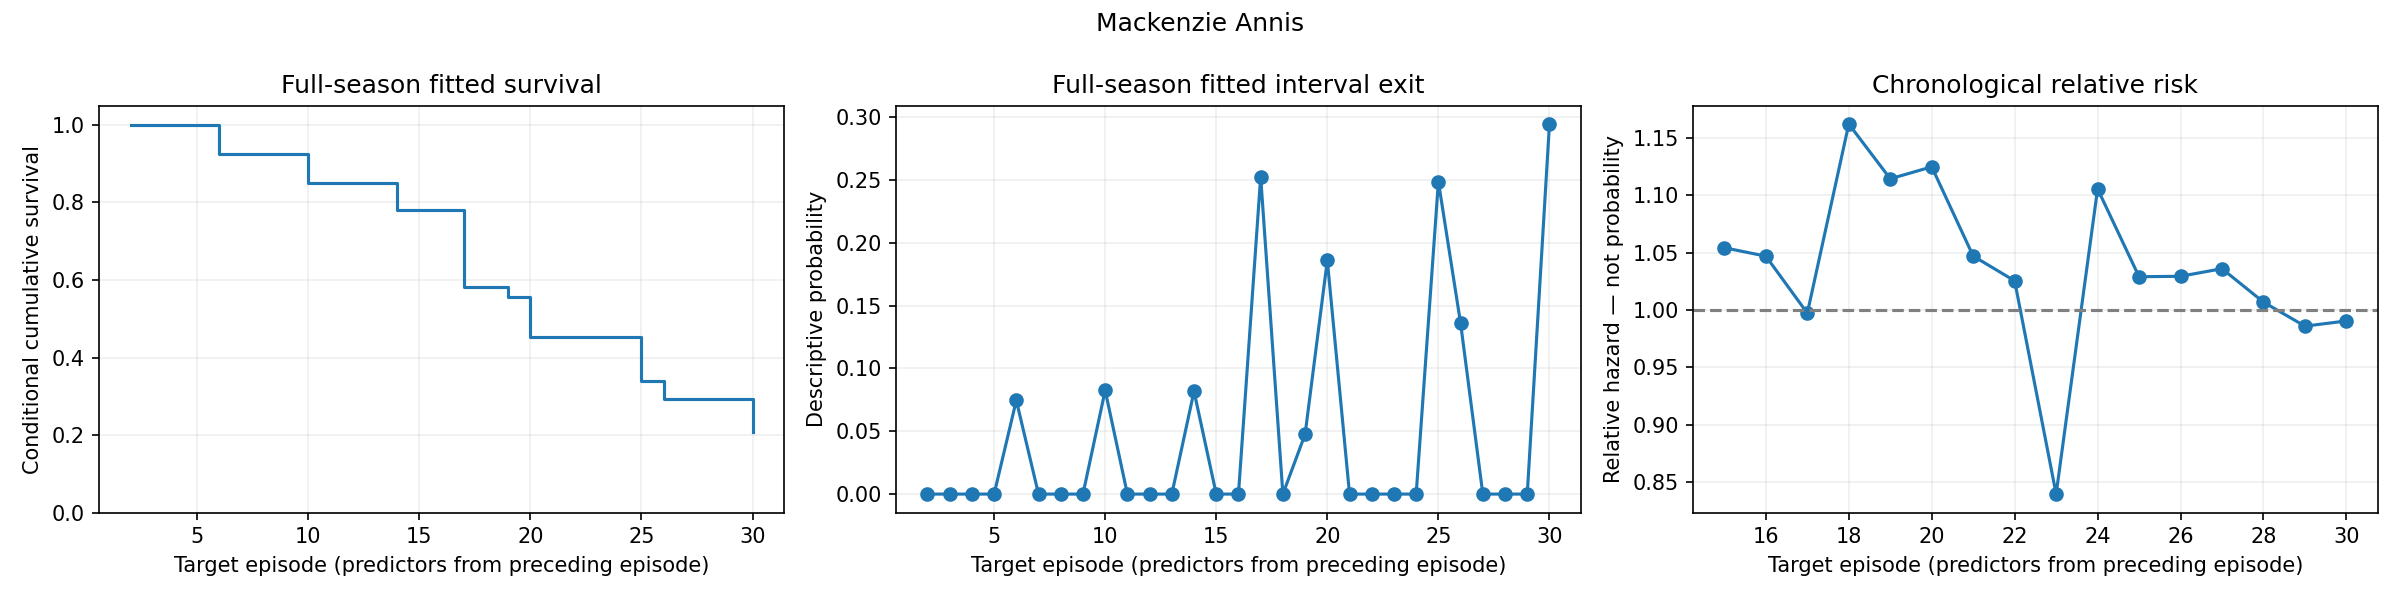

In [ ]:
# 5. Plot descriptive probabilities separately from chronological relative risk.
islander_to_inspect = "Mackenzie Annis"
islander_rows = time_varying_probabilities["target_islander"].eq(islander_to_inspect)
islander_time_varying = time_varying_probabilities.loc[islander_rows].copy()
chronological_islander_rows = chronological_cox_risk["target_islander"].eq(islander_to_inspect)
islander_chronological_risk = chronological_cox_risk.loc[chronological_islander_rows].copy()

time_varying_figure, time_varying_axes = plt.subplots(1, 3, figsize=(16, 4))
time_varying_axes[0].step(islander_time_varying["target_episode"], islander_time_varying["survival_probability"], where="post")
time_varying_axes[0].set_title("Full-season fitted survival")
time_varying_axes[0].set_ylabel("Conditional cumulative survival")
time_varying_axes[0].set_ylim(0, 1.05)
time_varying_axes[1].plot(islander_time_varying["target_episode"], islander_time_varying["booted_next_episode_probability"], marker="o")
time_varying_axes[1].set_title("Full-season fitted interval exit")
time_varying_axes[1].set_ylabel("Descriptive probability")
time_varying_axes[2].plot(islander_chronological_risk["target_episode"], islander_chronological_risk["relative_hazard"], marker="o")
time_varying_axes[2].axhline(1, color="gray", linestyle="--")
time_varying_axes[2].set_title("Chronological relative risk")
time_varying_axes[2].set_ylabel("Relative hazard — not probability")
for plot_axis in time_varying_axes:
    plot_axis.set_xlabel("Target episode (predictors from preceding episode)")
    plot_axis.grid(alpha=0.2)
time_varying_figure.suptitle(islander_to_inspect)
time_varying_figure.tight_layout()
time_varying_figure_path = project_root / "viz" / "time_varying_cox_diagnostics.png"
time_varying_figure.savefig(time_varying_figure_path, dpi=150)
plt.show()

# Identical or entirely missing predictor histories can still give constant relative risk.
risk_variation_summary = time_varying_probabilities.groupby("target_islander")["relative_hazard"].agg(["min", "max", "nunique"])
display(risk_variation_summary)


## 23. Save the time-varying Cox results

Save separate DuckDB and CSV tables so existing baseline-Cox/dashboard results are not silently relabeled. `cox_time_varying_probabilities` contains full-season descriptive probabilities. `cox_time_varying_chronological_risk` contains earlier-outcome-only **relative hazards**, not probabilities. Configuration and fold preprocessing record how each was produced. The dashboard currently continues to use its existing baseline-Cox curve until explicitly switched.

In [ ]:
# 6. Save estimates, coefficients, preprocessing, and provenance.
time_varying_configuration = {
    "model_version": time_varying_model_version,
    "time_scale": "broadcast episode",
    "interval": "(target_episode - 1, target_episode]",
    "covariates": time_varying_covariates,
    "penalizer": time_varying_penalty,
    "entry_rule": "exclude entry intervals; condition on first modeled interval",
    "cutoff": "earliest observed target-episode comment; retrospective proxy",
    "descriptive_probabilities": "full-season fit along observed lagged covariate history",
    "chronological_output": "relative hazard only; baseline hazard not extrapolated",
    "minimum_training_events": time_varying_minimum_training_events,
}
time_varying_configuration_json = json.dumps(time_varying_configuration, indent=2)
time_varying_configuration_table = pd.DataFrame([{"configuration_json": time_varying_configuration_json}])
time_varying_export_tables = {
    "cox_time_varying_probabilities": time_varying_probabilities,
    "cox_time_varying_coefficients": time_varying_coefficients,
    "cox_time_varying_preprocessing": time_varying_preprocessing,
    "cox_time_varying_baseline_hazard": time_varying_baseline_hazard,
    "cox_time_varying_chronological_risk": chronological_cox_risk,
    "cox_time_varying_folds": chronological_cox_folds,
    "cox_time_varying_fold_coefficients": chronological_cox_coefficients,
    "cox_time_varying_fold_preprocessing": chronological_cox_preprocessing,
    "cox_time_varying_configuration": time_varying_configuration_table,
}
time_varying_export_directory = project_root / "tables" / "survival_dashboard"
time_varying_export_directory.mkdir(parents=True, exist_ok=True)
with duckdb.connect(str(database_path)) as connection:
    connection.execute("BEGIN TRANSACTION")
    try:
        for table_name, export_dataset in time_varying_export_tables.items():
            export_dataset["model_version"] = time_varying_model_version
            export_dataset["model_run_time"] = time_varying_run_time
            connection.register("time_varying_export", export_dataset)
            connection.execute(f"CREATE OR REPLACE TABLE dashboard.{table_name} AS SELECT * FROM time_varying_export")
            saved_dataset = connection.execute(f"SELECT * FROM dashboard.{table_name}").df()
            pd.testing.assert_frame_equal(saved_dataset, export_dataset.reset_index(drop=True), check_dtype=False)
            connection.unregister("time_varying_export")
        connection.execute("COMMIT")
    except Exception:
        connection.execute("ROLLBACK")
        raise
for table_name, export_dataset in time_varying_export_tables.items():
    export_path = time_varying_export_directory / f"{table_name}.csv"
    export_dataset.to_csv(export_path, index=False, encoding="utf-8")
    print(f"Saved dashboard.{table_name}: {len(export_dataset)} rows — DuckDB and CSV")

Saved dashboard.cox_time_varying_probabilities: 503 rows — DuckDB and CSV
Saved dashboard.cox_time_varying_coefficients: 6 rows — DuckDB and CSV
Saved dashboard.cox_time_varying_preprocessing: 6 rows — DuckDB and CSV
Saved dashboard.cox_time_varying_baseline_hazard: 36 rows — DuckDB and CSV
Saved dashboard.cox_time_varying_chronological_risk: 503 rows — DuckDB and CSV
Saved dashboard.cox_time_varying_folds: 34 rows — DuckDB and CSV
Saved dashboard.cox_time_varying_fold_coefficients: 126 rows — DuckDB and CSV
Saved dashboard.cox_time_varying_fold_preprocessing: 126 rows — DuckDB and CSV
Saved dashboard.cox_time_varying_configuration: 1 rows — DuckDB and CSV


## 24. Build the interactive network dashboard

This dashboard reads the saved tables from 07 and 08; it does not refit models. It preserves all 34 overall nodes, the fixed layout, community colors, and episode-specific metrics. The default episode filter matches 07: islanders remain through their final exit episode. “Include departed” shows all islanders with discussion in the selected episode. Edge filtering never drops isolated nodes.

Choose an episode, click an islander, then inspect their connections, emojis, approval, sentiment, toxicity, and trends. Enable focus to enlarge their neighborhood. The expandable **Experimental models** panel separates next-episode logistic forecasts from full-season descriptive Cox survival. Unavailable estimates remain unavailable, not zero. The overall view shows curves but does not average episode probabilities.

The output is a standalone local HTML file with Plotly and data included. Open the link below in a browser for the largest view; rebuilding refreshes it from DuckDB.

In [5]:
# 1. Locate the existing project.
from pathlib import Path
import importlib.util
from IPython.display import display, HTML, IFrame

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# 2. Build from the saved results, without rerunning any model.
dashboard_builder_path = project_root / "code" / "build_network_dashboard.py"
dashboard_specification = importlib.util.spec_from_file_location("network_dashboard_builder", dashboard_builder_path)
dashboard_builder = importlib.util.module_from_spec(dashboard_specification)
dashboard_specification.loader.exec_module(dashboard_builder)
dashboard_path = dashboard_builder.build_network_dashboard(project_root)

# 3. Show a link and a notebook preview.
dashboard_relative_path = "../viz/dashboard/index.html"
if Path.cwd() == project_root:
    dashboard_relative_path = "viz/dashboard/index.html"
display(HTML(f'<a href="{dashboard_relative_path}" target="_blank">Open the full interactive dashboard</a>'))
display(IFrame(src=dashboard_relative_path, width="100%", height=1000))

Dashboard saved: /Users/edieespejo/GitHub/data-by-edie/004-love-island/viz/dashboard/index.html
Preserved all 34 islanders from notebook 07.
